# 771762 Big Data and Data Mining - Exercise 1
# Analysis of UK Traffic Accident Data (2018)

**Module:** Big Data and Data Mining (771762)  
**Exercise:** 1 - Road Traffic Accident Analysis  
**Dataset:** `accident_data_v1.0.0_2023.db`  
**Code reference:** STATS20 2011 edition, Department for Transport

---

| Section | Content |
|---|---|
| 0 | Setup & Imports |
| 0b | STATS20 Code Lookup Tables |
| 1 | Data Loading & Cleaning |
| 2 | Task 1 – Temporal Patterns (All Accidents) |
| 3 | Task 2 – Motorcycle Accident Patterns |
| 4 | Task 3 – Pedestrian Accident Patterns |
| 5 | Task 4 – Apriori Association Rule Mining |
| 6 | Task 5 – Clustering in West Yorkshire |
| 7 | Task 6 – Time Series Forecasting by Police Area |
| 8 | Task 7 – Top-30 LSOA Daily Forecast (West Yorkshire) |

## Setup and Imports

In [1]:
import sqlite3, warnings, itertools
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox

from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, mean_squared_error
from sklearn.metrics import mean_absolute_percentage_error
from scipy.stats import chi2_contingency

from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder

sns.set_theme(style='whitegrid', palette='tab10')
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})

DB_PATH = 'accident_data_v1.0.0_2023.db'  
print('Imports OK.')

Imports OK.


---
## STATS20 Code Lookup Tables

Every mapping below is taken verbatim from the **STATS20 (2011) manual** published by the
Department for Transport. 

In [2]:
# ============================================================
# STATS20 (2011) – Accident / Attendant Circumstances (Annex 1)
# ============================================================

# §1.12 / §1.18  Road class
ROAD_CLASS = {1:'Motorway', 2:'A(M)', 3:'A', 4:'B', 5:'C', 6:'Unclassified'}

# §1.14  Road type
ROAD_TYPE = {1:'Roundabout', 2:'One-way street', 3:'Dual carriageway',
             6:'Single carriageway', 7:'Slip road', 9:'Unknown'}

# §1.16  Junction detail
JUNCTION_DETAIL = {
    0:'Not at junction',         1:'Roundabout',
    2:'Mini-roundabout',         3:'T or staggered junction',
    5:'Slip road',               6:'Crossroads',
    7:'Junction >4 arms',        8:'Private drive/entrance',
    9:'Other junction'
}

# §1.17  Junction control
JUNCTION_CONTROL = {1:'Authorised person', 2:'Traffic signal',
                    3:'Stop sign', 4:'Give way/uncontrolled'}

# §1.20a  Pedestrian crossing – human control
PED_CROSS_HUMAN = {0:'None within 50m', 1:'School crossing patrol',
                   2:'Other authorised person'}

# §1.20b  Pedestrian crossing – physical facilities
PED_CROSS_PHYSICAL = {
    0:'No facility within 50m',  1:'Zebra crossing',
    4:'Pelican/puffin/toucan',   5:'Pedestrian phase at signal junction',
    7:'Footbridge or subway',    8:'Central refuge – no other controls'
}

# §1.21  Light conditions
LIGHT_CONDITIONS = {
    1:'Daylight',
    4:'Darkness – street lights lit',
    5:'Darkness – street lights unlit',
    6:'Darkness – no street lighting',
    7:'Darkness – lighting unknown'
}

# §1.22  Weather
WEATHER = {
    1:'Fine, no high winds',     2:'Raining, no high winds',
    3:'Snowing, no high winds',  4:'Fine with high winds',
    5:'Raining with high winds', 6:'Snowing with high winds',
    7:'Fog or mist',             8:'Other',  9:'Unknown'
}

# §1.23  Road surface condition
ROAD_SURFACE = {
    1:'Dry', 2:'Wet/Damp', 3:'Snow',
    4:'Frost/Ice', 5:'Flood (>3cm surface water)'
}

# §1.24  Special conditions at site
SPECIAL_CONDITIONS = {
    0:'None',                              1:'Traffic signal out',
    2:'Traffic signal partially defective',3:'Road signing/marking defective',
    4:'Roadworks',                         5:'Road surface defective',
    6:'Oil or diesel',                     7:'Mud'
}

# §1.25  Carriageway hazards
CARRIAGEWAY_HAZARDS = {
    0:'None',                       1:'Dislodged vehicle load',
    2:'Other object in carriageway', 3:'Involvement with previous accident',
    6:'Pedestrian in carriageway (not injured)',
    7:'Animal in carriageway (not ridden horse)'
}

# §1.26  Did police officer attend?
POLICE_ATTENDED = {1:'Yes', 2:'No', 3:'No – self-report form'}

# Urban/rural (standard DfT field accompanying STATS19)
URBAN_RURAL = {1:'Urban', 2:'Rural', 3:'Unallocated'}

# Accident severity (derived from highest casualty severity – §3.9)
ACCIDENT_SEVERITY = {1:'Fatal', 2:'Serious', 3:'Slight'}

# ============================================================
# STATS20 – Vehicle Variables (Annex 2)
# ============================================================

# §2.5  Vehicle type
VEHICLE_TYPE = {
     1:'Pedal cycle',
     2:'Motorcycle ≤50cc',
     3:'Motorcycle 51–125cc',
     4:'Motorcycle 126–500cc',
     5:'Motorcycle >500cc',
    97:'Motorcycle – unknown cc',
    23:'Electric motorcycle',
     8:'Taxi/Private hire car',
     9:'Car',
    10:'Minibus (8–16 seats)',
    11:'Bus or coach (17+ seats)',
    16:'Ridden horse',
    17:'Agricultural vehicle',
    18:'Tram/Light rail',
    19:'Van/Goods vehicle ≤3.5t',
    20:'Goods vehicle 3.5–7.5t',
    21:'Goods vehicle ≥7.5t',
    98:'Goods vehicle – unknown weight',
    22:'Mobility scooter',
    90:'Other vehicle'
}

# §2.6  Towing and articulation
TOWING = {
    0:'No tow/articulation', 1:'Articulated', 2:'Double/multiple trailer',
    3:'Caravan', 4:'Single trailer', 5:'Other tow'
}

# §2.7  Vehicle manoeuvre (immediately before accident)
MANOEUVRE = {
     1:'Reversing',              2:'Parked',
     3:'Waiting to go ahead',   4:'Slowing/stopping',
     5:'Moving off',            6:'U-turn',
     7:'Turning left',          8:'Waiting to turn left',
     9:'Turning right',        10:'Waiting to turn right',
    11:'Changing lane left',   12:'Changing lane right',
    13:'Overtaking moving (offside)', 14:'Overtaking stationary (offside)',
    15:'Overtaking (nearside)',  16:'Going ahead – left bend',
    17:'Going ahead – right bend', 18:'Going ahead – other'
}

# §2.9  Vehicle location (restricted lane / off main carriageway)
VEH_LOCATION = {
    0:'Main carriageway',        1:'Tram/light rail track',
    2:'Bus lane',                3:'Busway (incl. guided)',
    4:'Cycle lane',              5:'Cycleway/shared use footway',
    6:'On lay-by/hard shoulder', 7:'Entering lay-by/hard shoulder',
    8:'Leaving lay-by/hard shoulder', 9:'Footway (pavement)'
}

# §2.10  Junction location of vehicle
JUNCTION_LOC_VEH = {
    0:'Not at junction',  1:'Approaching junction',
    2:'Cleared junction', 3:'Leaving roundabout',
    4:'Entering roundabout', 5:'Leaving main road',
    6:'Entering main road',  7:'Entering from slip road',
    8:'Mid junction'
}

# §2.11  Skidding and overturning
SKIDDING = {
    0:'None', 1:'Skidded', 2:'Skidded and overturned',
    3:'Jack-knifed', 4:'Jack-knifed and overturned', 5:'Overturned'
}

# §2.16  First point of impact
FIRST_IMPACT = {0:'Did not impact', 1:'Front', 2:'Back', 3:'Offside', 4:'Nearside'}

# §2.21  Sex of driver
SEX_DRIVER = {1:'Male', 2:'Female', 3:'Not known'}

# §2.23  Breath test
BREATH_TEST = {
    0:'Not applicable', 1:'Positive', 2:'Negative',
    3:'Not requested',  4:'Refused',
    5:'Driver not contacted', 6:'Not provided (medical)'
}

# §2.24  Hit and run
HIT_AND_RUN = {0:'Other', 1:'Hit and run', 2:'Non-stop vehicle, not hit'}

# §2.29  Journey purpose of driver/rider
JOURNEY_PURPOSE = {
    1:'Journey as part of work', 2:'Commuting to/from work',
    3:'Taking pupil to/from school', 4:'Pupil riding to/from school',
    5:'Other', 6:'Not known'
}

# §2.35  Left hand drive
LEFT_HAND_DRIVE = {1:'No', 2:'Yes'}

# ============================================================
# STATS20 – Casualty Variables (Annex 3)
# ============================================================

# §3.6  Casualty class
CASUALTY_CLASS = {1:'Driver or rider', 2:'Vehicle/pillion passenger', 3:'Pedestrian'}

# §3.7  Sex of casualty
SEX_CASUALTY = {1:'Male', 2:'Female'}

# §3.9  Casualty severity
# Fatal = death within 30 days; Serious = fractures/hospital; Slight = whiplash/bruising
CASUALTY_SEVERITY = {1:'Fatal', 2:'Serious', 3:'Slight'}

# §3.10  Pedestrian location
PED_LOCATION = {
     1:'Crossing on ped crossing facility',
     2:'Crossing – zig-zag approach',
     3:'Crossing – zig-zag exit',
     4:'Crossing within 50m of crossing',
     5:'Crossing elsewhere',
     6:'On footway or verge',
     7:'On refuge/central island/reservation',
     8:'In centre of carriageway (not refuge)',
     9:'In carriageway, not crossing',
    10:'Unknown or other'
}

# §3.11  Pedestrian movement
PED_MOVEMENT = {
    1:'Crossing from nearside',
    2:'Crossing nearside – masked by vehicle',
    3:'Crossing from offside',
    4:'Crossing offside – masked by vehicle',
    5:'Stationary in carriageway',
    6:'Stationary – masked by vehicle',
    7:'Walking – facing traffic',
    8:'Walking – back to traffic',
    9:'Unknown or other'
}

# §3.14  Seat belt in use (fatal accidents; required by STATS20)
SEAT_BELT = {
    0:'Not applicable', 1:'Worn – confirmed', 2:'Worn – not confirmed',
    3:'Not worn', 4:'Unknown'
}

# §3.15  Car passenger
CAR_PASSENGER = {0:'Not a car passenger', 1:'Front seat', 2:'Rear seat'}

# §3.16  Bus/coach passenger
BUS_PASSENGER = {
    0:'Not a bus/coach passenger', 1:'Boarding', 2:'Alighting',
    3:'Standing passenger', 4:'Seated passenger'
}

# §3.19  Pedestrian road maintenance worker
PED_ROAD_WORKER = {0:'Not applicable', 1:'Yes', 2:'Not known'}

# §3.20  Cycle helmet worn
CYCLE_HELMET = {0:'Not a cyclist', 1:'Yes', 2:'No', 3:'Not known'}

# ============================================================
# STATS20 – Annex 6  Police Force Codes
# ============================================================
POLICE_FORCE = {
    # England
     1:'Metropolitan Police',  3:'Cumbria',            4:'Lancashire',
     5:'Merseyside',           6:'Greater Manchester',  7:'Cheshire',
    10:'Northumbria',         11:'Durham',             12:'North Yorkshire',
    13:'West Yorkshire',      14:'South Yorkshire',    16:'Humberside',
    17:'Cleveland',           20:'West Midlands',      21:'Staffordshire',
    22:'West Mercia',         23:'Warwickshire',       30:'Derbyshire',
    31:'Nottinghamshire',     32:'Lincolnshire',       33:'Leicestershire',
    34:'Northamptonshire',    35:'Cambridgeshire',     36:'Norfolk',
    37:'Suffolk',             40:'Bedfordshire',       41:'Hertfordshire',
    42:'Essex',               43:'Thames Valley',      44:'Hampshire',
    45:'Surrey',              46:'Kent',               47:'Sussex',
    48:'City of London',      50:'Devon and Cornwall', 52:'Avon and Somerset',
    53:'Gloucestershire',     54:'Wiltshire',          55:'Dorset',
    # Wales
    60:'North Wales',         61:'Gwent',              62:'South Wales',
    63:'Dyfed-Powys',
    # Scotland
    91:'Northern',            92:'Grampian',           93:'Tayside',
    94:'Fife',                95:'Lothian and Borders', 96:'Central',
    97:'Strathclyde',         98:'Dumfries and Galloway'
}

# ============================================================
# Derived constants used throughout the notebook
# ============================================================

# DfT 2024: day_of_week codes  1=Sunday … 7=Saturday
DOW_MAP   = {1:'Sunday',2:'Monday',3:'Tuesday',4:'Wednesday',
             5:'Thursday',6:'Friday',7:'Saturday'}
DAY_ORDER = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']

# Motorcycle codes grouped for the three assignment categories (STATS20 §2.5)
# Group 1 – ≤125cc:  codes 2 (≤50cc) + 3 (51-125cc)
# Group 2 – 126-500cc: code 4
# Group 3 – >500cc:  code 5
MOTO_GROUP_MAP = {
    2:'Motorcycle ≤125cc',
    3:'Motorcycle ≤125cc',
    4:'Motorcycle 126–500cc',
    5:'Motorcycle >500cc'
}
MOTO_GROUP_ORDER = ['Motorcycle ≤125cc','Motorcycle 126–500cc','Motorcycle >500cc']
MOTO_COLOURS     = {'Motorcycle ≤125cc':'#1f77b4',
                    'Motorcycle 126–500cc':'#ff7f0e',
                    'Motorcycle >500cc':'#2ca02c'}

# West Yorkshire police force code (STATS20 Annex 6)
WY_POLICE_CODE = 13

# Three police areas for Task 6 (STATS20 Annex 6)
POLICE_AREAS = {
     1:'Metropolitan Police',
    13:'West Yorkshire',
    43:'Thames Valley'
}

print('All STATS20 lookup tables loaded.')

All STATS20 lookup tables loaded.


---
## Section 1 - Data Loading & Cleaning

In [3]:
def open_db(path: str = DB_PATH) -> sqlite3.Connection:
    """Open a read-only SQLite connection."""
    return sqlite3.connect(f'file:{path}?mode=ro', uri=True)

def load_table(query: str, conn: sqlite3.Connection) -> pd.DataFrame:
    """Execute query and return DataFrame."""
    return pd.read_sql_query(query, conn)

with open_db() as conn:
    acc_all  = load_table('SELECT * FROM accident', conn)
    veh_all  = load_table('SELECT * FROM vehicle', conn)
    cas_all  = load_table('SELECT * FROM casualty', conn)
    lsoa_tbl = load_table('SELECT * FROM lsoa', conn)

print(f'Accident rows : {len(acc_all):,}')
print(f'Vehicle rows  : {len(veh_all):,}')
print(f'Casualty rows : {len(cas_all):,}')

Accident rows : 461,352
Vehicle rows  : 849,091
Casualty rows : 600,332


In [4]:
def parse_accident_datetime(df: pd.DataFrame) -> pd.DataFrame:
    """
    Parse date/time and attach human-readable label columns using
    verified STATS20 code dictionaries.
    Note: day_of_week in STATS20 §1.7 runs 1=Sunday … 7=Saturday.
    """
    df = df.copy()
    df['date']  = pd.to_datetime(df['date'], dayfirst=True, errors='coerce')
    df['hour']  = (pd.to_datetime(df['time'].astype(str),
                                  format='%H:%M', errors='coerce')
                   .dt.hour)
    df['year']  = df['date'].dt.year
    df['month'] = df['date'].dt.month
    df['week']  = df['date'].dt.isocalendar().week.astype(int)

    # STATS20 §1.7 – day of week
    df['day_name'] = df['day_of_week'].map(DOW_MAP)

    # Readable label columns (used in charts throughout)
    df['severity_label']     = df['accident_severity'].map(ACCIDENT_SEVERITY)
    df['light_label']        = df['light_conditions'].map(LIGHT_CONDITIONS)
    df['weather_label']      = df['weather_conditions'].map(WEATHER)
    df['surface_label']      = df['road_surface_conditions'].map(ROAD_SURFACE)
    df['road_type_label']    = df['road_type'].map(ROAD_TYPE)
    df['junction_label']     = df['junction_detail'].map(JUNCTION_DETAIL)
    df['junction_control_label'] = df['junction_control'].map(JUNCTION_CONTROL)
    df['special_cond_label'] = df['special_conditions_at_site'].map(SPECIAL_CONDITIONS)
    df['urban_rural_label']  = df['urban_or_rural_area'].map(URBAN_RURAL)
    df['police_force_label'] = df['police_force'].map(POLICE_FORCE)
    df['road_class_label']   = df['first_road_class'].map(ROAD_CLASS)
    df['ped_cross_human_control_label'] = df['pedestrian_crossing_human_control'].map(PED_CROSS_HUMAN)
    df['ped_cross_phys_facility_label'] = df['pedestrian_crossing_physical_facilities'].map(PED_CROSS_PHYSICAL)
    return df

acc_all = parse_accident_datetime(acc_all)

before = len(acc_all)
acc_all.dropna(subset=['date','hour','latitude','longitude'], inplace=True)
print(f'Rows dropped (missing critical fields): {before - len(acc_all):,}')

acc_2018 = acc_all[acc_all['year'] == 2018].copy()
print(f'2018 accident records: {len(acc_2018):,}')

Rows dropped (missing critical fields): 126
2018 accident records: 122,580


In [5]:
# ── Data quality report ────────────────────────────────────────────────────────
print('=== Missing value summary (2018 accident table) ===')
miss = (acc_2018.isnull().sum() / len(acc_2018) * 100).round(2)
print(miss[miss > 0].to_string())

print('\n=== Severity distribution (STATS20 §3.9) ===')
print(acc_2018['severity_label'].value_counts())

print('\n=== Top 10 police forces in data (STATS20 Annex 6) ===')
print(acc_2018['police_force_label'].value_counts().head(10))

print('\n=== Light condition distribution (STATS20 §1.21) ===')
print(acc_2018['light_label'].value_counts())

=== Missing value summary (2018 accident table) ===
weather_label                     0.01
surface_label                     1.00
junction_label                    0.63
junction_control_label           44.72
special_cond_label                1.24
ped_cross_human_control_label     2.59
ped_cross_phys_facility_label     2.32

=== Severity distribution (STATS20 §3.9) ===
severity_label
Slight     97953
Serious    22957
Fatal       1670
Name: count, dtype: int64

=== Top 10 police forces in data (STATS20 Annex 6) ===
police_force_label
Metropolitan Police    25384
West Midlands           5489
Kent                    4401
West Yorkshire          4132
Hampshire               3957
Sussex                  3859
Thames Valley           3832
Greater Manchester      3762
Devon and Cornwall      3447
Lancashire              3376
Name: count, dtype: int64

=== Light condition distribution (STATS20 §1.21) ===
light_label
Daylight                          88398
Darkness – street lights lit      24734


---
## Section 2 - Task 1: Temporal Accident Patterns (All Vehicles, 2018)

- Day-of-week codes: ** DfT 2024** (1=Sunday … 7=Saturday) → mapped via `DOW_MAP`.
- Accident severity codes: **STATS20 §3.9** (1=Fatal, 2=Serious, 3=Slight).

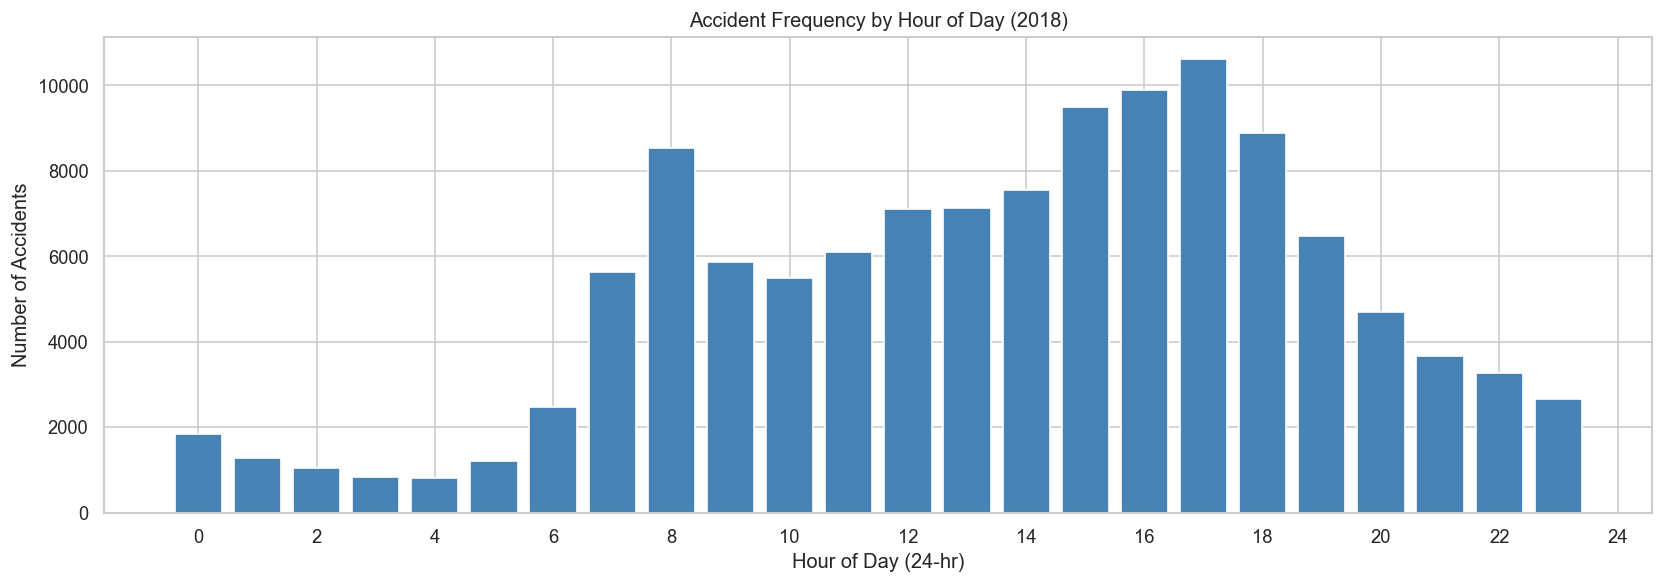

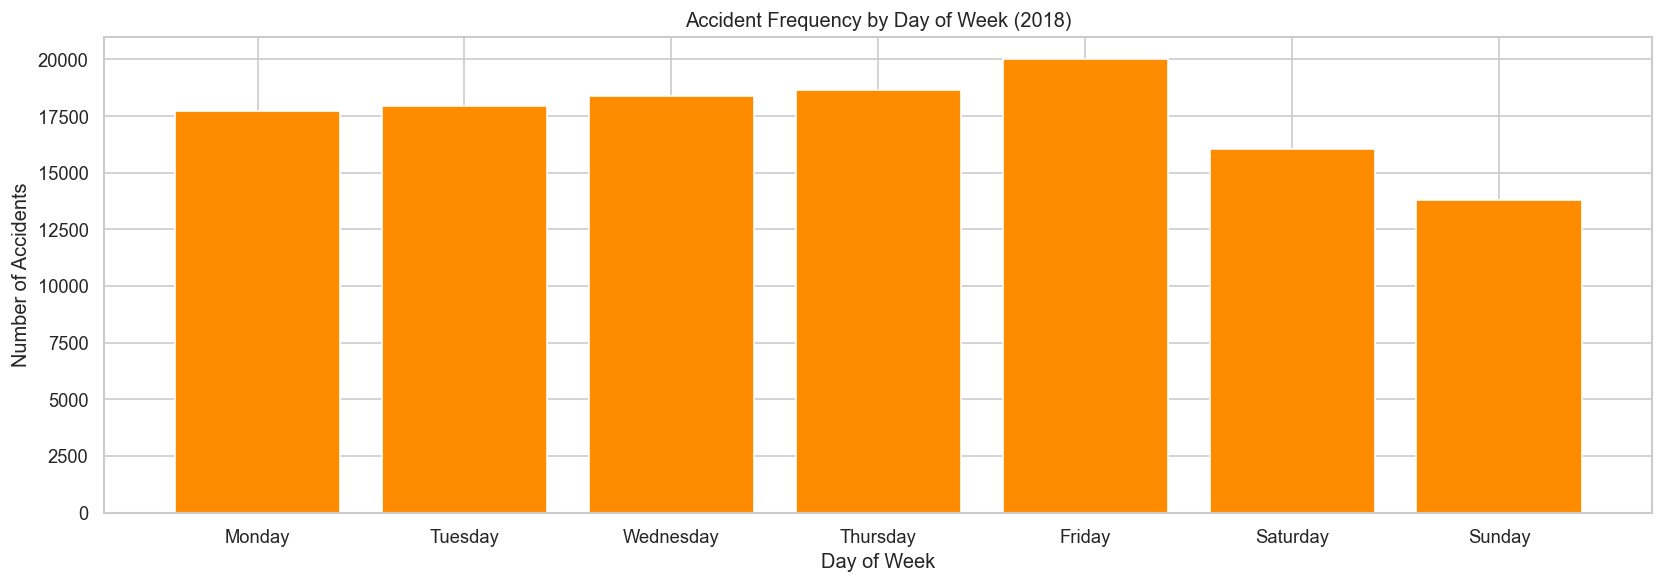

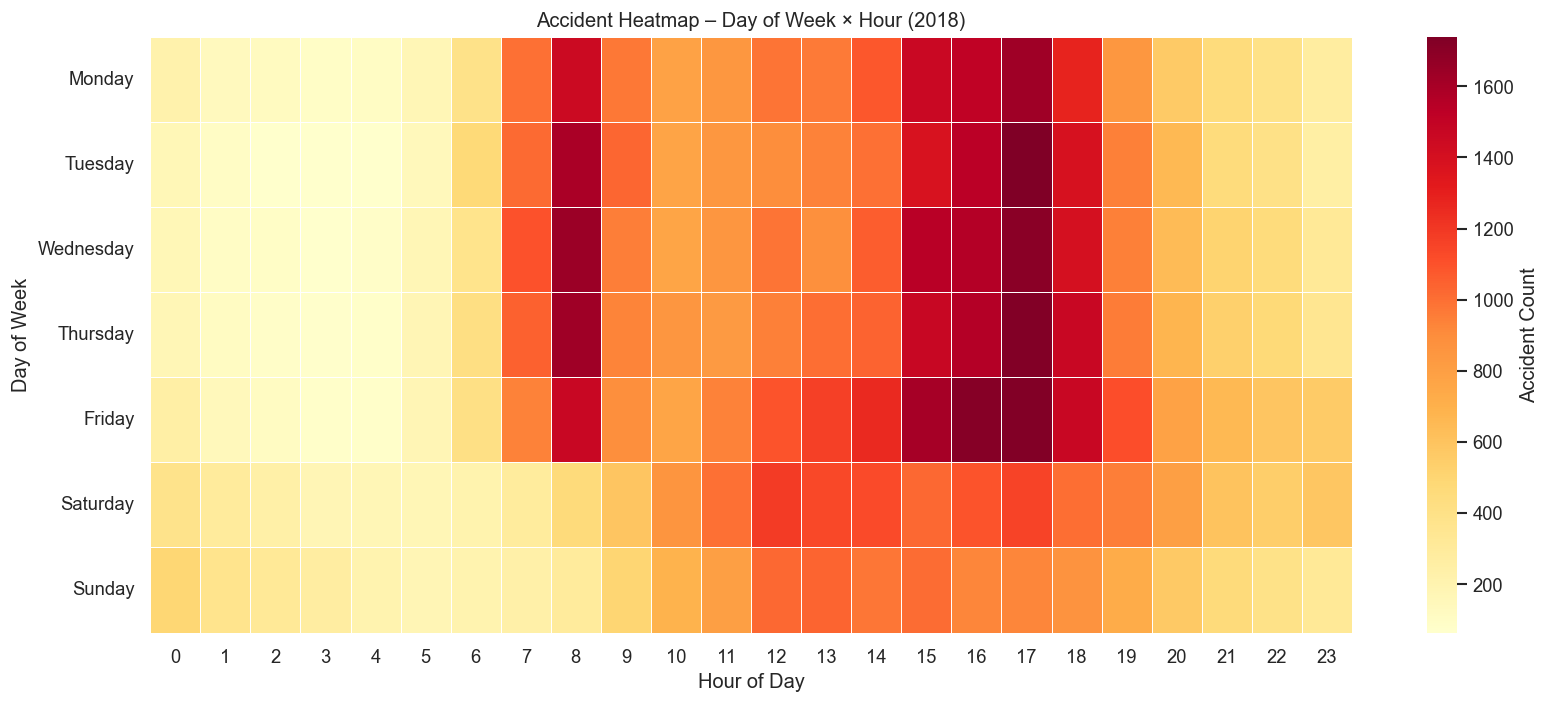

Peak hour: 17:00
Peak day : Friday


In [6]:
hourly    = acc_2018.groupby('hour').size().reset_index(name='count')
daily     = (acc_2018.groupby('day_name').size()
             .reindex(DAY_ORDER).reset_index(name='count'))
heat_data = (acc_2018.groupby(['day_name','hour']).size()
             .unstack(fill_value=0).reindex(DAY_ORDER))

# ---- Plot 1: Hourly ----
plt.figure(figsize=(14, 5))
plt.bar(hourly['hour'], hourly['count'], color='steelblue', edgecolor='white')
plt.title('Accident Frequency by Hour of Day (2018)')
plt.xlabel('Hour of Day (24-hr)')
plt.ylabel('Number of Accidents')
plt.gca().xaxis.set_major_locator(ticker.MultipleLocator(2))
plt.tight_layout()
plt.savefig('task1_hourly.png', bbox_inches='tight')
plt.show()

# ---- Plot 2: Daily ----
plt.figure(figsize=(14, 5))
plt.bar(daily['day_name'], daily['count'], color='darkorange', edgecolor='white')
plt.title('Accident Frequency by Day of Week (2018)')
plt.xlabel('Day of Week')
plt.ylabel('Number of Accidents')
plt.tight_layout()
plt.savefig('task1_daily.png', bbox_inches='tight')
plt.show()

# ---- Plot 3: Heatmap ----
plt.figure(figsize=(14, 6))
sns.heatmap(heat_data, cmap='YlOrRd', linewidths=0.3,
            cbar_kws={'label':'Accident Count'})
plt.title('Accident Heatmap – Day of Week × Hour (2018)')
plt.xlabel('Hour of Day')
plt.ylabel('Day of Week')
plt.tight_layout()
plt.savefig('task1_heatmap.png', bbox_inches='tight')
plt.show()

print(f'Peak hour: {hourly.loc[hourly["count"].idxmax(),"hour"]}:00')
print(f'Peak day : {daily.loc[daily["count"].idxmax(),"day_name"]}')

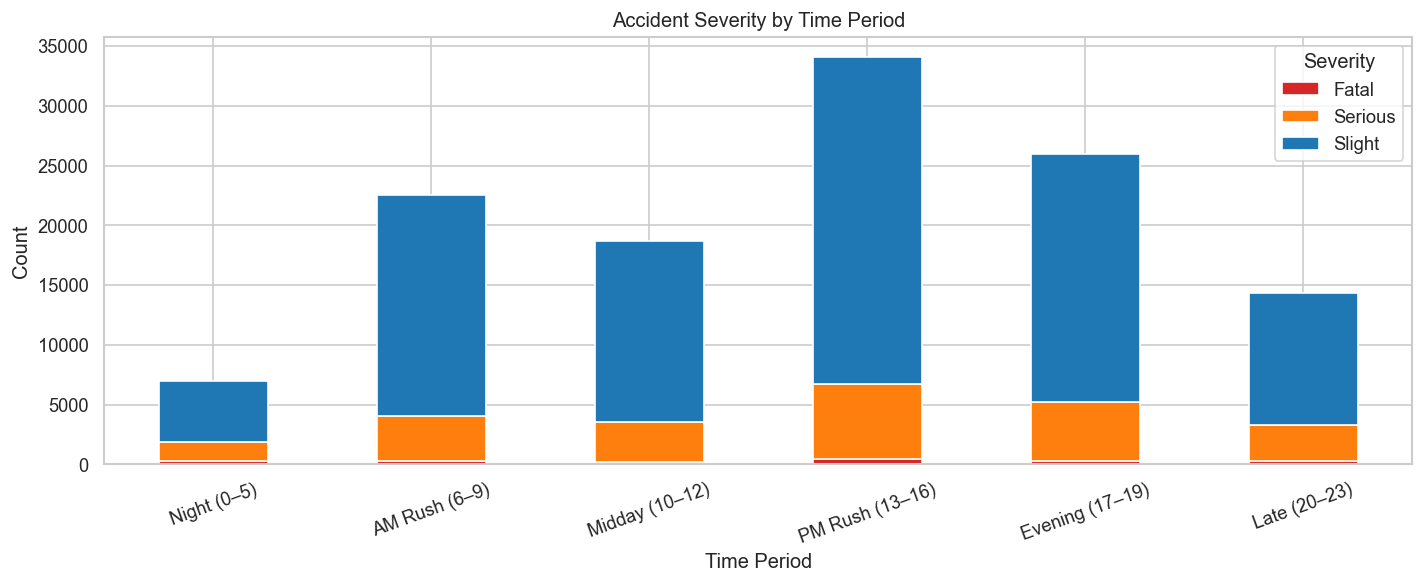

In [7]:
# Severity breakdown by time-of-day band
acc_2018['time_period'] = pd.cut(
    acc_2018['hour'],
    bins=[-1,5,9,12,16,19,23],
    labels=['Night (0–5)','AM Rush (6–9)','Midday (10–12)',
            'PM Rush (13–16)','Evening (17–19)','Late (20–23)']
)
sev_period = acc_2018.groupby(['time_period','severity_label']).size().unstack(fill_value=0)
# Reorder columns to Fatal / Serious / Slight (STATS20 §3.9 code order)
for col in ['Fatal','Serious','Slight']:
    if col not in sev_period.columns:
        sev_period[col] = 0
sev_period = sev_period[['Fatal','Serious','Slight']]

sev_period.plot(kind='bar', stacked=True, figsize=(12,5),
                color=['#d62728','#ff7f0e','#1f77b4'])
plt.title('Accident Severity by Time Period')
plt.xlabel('Time Period'); plt.ylabel('Count')
plt.xticks(rotation=20)
plt.legend(title='Severity')
plt.tight_layout()
plt.savefig('task1_severity_by_period.png', bbox_inches='tight')
plt.show()

## CHI-SQUARE  Tests To Identify Significant Accident Factors

In [8]:
# ---------------------------------------------------------
# 1. PREPARE ACCIDENT DATA
# ---------------------------------------------------------

# Use the already cleaned 2018 accident table
acc = acc_2018.copy()

# Create time-of-day bands
acc['time_period'] = pd.cut(
    acc['hour'],
    bins=[-1,5,9,12,16,19,23],
    labels=['Night (0-5)','AM Rush (6-9)','Midday (10-12)',
            'PM Rush (13-16)','Evening (17-19)','Late (20-23)']
)

# ---------------------------------------------------------
# 2. CHI-SQUARE TESTS TO IDENTIFY SIGNIFICANT FACTORS
# ---------------------------------------------------------

def chi_square(df, feature):
    """
    Tests whether the distribution of a feature differs across time periods.
    """
    table = pd.crosstab(df['time_period'], df[feature])
    chi2, p, dof, expected = chi2_contingency(table)
    return table, p

features = [
    'severity_label', 'light_label', 'weather_label',
    'urban_rural_label', 'road_type_label', 'road_class_label', 'junction_label', 
    'junction_control_label',
    'special_cond_label', 'surface_label'
]

sig_results = {}

for f in features:
    table, p = chi_square(acc, f)
    sig_results[f] = {'table': table, 'p_value': p}

print("\n=== SIGNIFICANT TEMPORAL DIFFERENCES (p < 0.05) ===\n")
for f, res in sig_results.items():
    if res['p_value'] < 0.05:
        print(f"{f}: p = {res['p_value']:.5f}")
        print(res['table'])
        print("\n")

# ---------------------------------------------------------
# 3. OVER-REPRESENTATION ANALYSIS
# ---------------------------------------------------------

def overrepresented(df, feature):
    """
    Computes percentage distribution of a feature per time period.
    Helps identify which conditions dominate each time window.
    """
    return (
        df.groupby('time_period')[feature]
        .value_counts(normalize=True)
        .rename('proportion')
        .mul(100)
        .reset_index()
        .sort_values(['time_period', 'proportion'], ascending=[True, False])
    )

overrep = {}

for f in features:
    overrep[f] = overrepresented(acc, f)

# Show top 5 for each feature
for f in features:
    print(f"\n=== Overrepresented Conditions for {f} ===")
    print(overrep[f].groupby('time_period').head(5))



=== SIGNIFICANT TEMPORAL DIFFERENCES (p < 0.05) ===

severity_label: p = 0.00000
severity_label   Fatal  Serious  Slight
time_period                            
Night (0-5)        252     1575    5169
AM Rush (6-9)      243     3804   18478
Midday (10-12)     219     3346   15143
PM Rush (13-16)    398     6316   27370
Evening (17-19)    273     4917   20778
Late (20-23)       285     2999   11015


light_label: p = 0.00000
light_label      Darkness – lighting unknown  Darkness – no street lighting  \
time_period                                                                   
Night (0-5)                              391                           1372   
AM Rush (6-9)                            272                            466   
Midday (10-12)                            18                             31   
PM Rush (13-16)                          194                            376   
Evening (17-19)                          843                           1740   
Late (20-23)      

---
## Section 3 – Task 2: Motorcycle Accident Patterns (2018)

Vehicle type codes (**STATS20 §2.5**):

| Code | Description | Group for this task |
|---|---|---|
| 02 | Motorcycle ≤50cc | ≤125cc |
| 03 | Motorcycle 51–125cc | ≤125cc |
| 04 | Motorcycle 126–500cc | 126–500cc |
| 05 | Motorcycle >500cc | >500cc |

In [9]:
veh_2018 = veh_all[veh_all['accident_year'] == 2018].copy()
veh_2018['vehicle_type_label'] = veh_2018['vehicle_type'].map(VEHICLE_TYPE)

moto_veh = veh_2018[veh_2018['vehicle_type'].isin(MOTO_GROUP_MAP.keys())].copy()
moto_veh['moto_group'] = moto_veh['vehicle_type'].map(MOTO_GROUP_MAP)

moto_acc = moto_veh.merge(
    acc_2018[['accident_index','hour','day_name','severity_label',
               'light_label','urban_rural_label','weather_label']],
    on='accident_index', how='inner'
)
print(f'Motorcycle accident records (2018): {len(moto_acc):,}')
print(moto_acc['moto_group'].value_counts())

Motorcycle accident records (2018): 17,470
moto_group
Motorcycle ≤125cc       9358
Motorcycle >500cc       5872
Motorcycle 126–500cc    2240
Name: count, dtype: int64


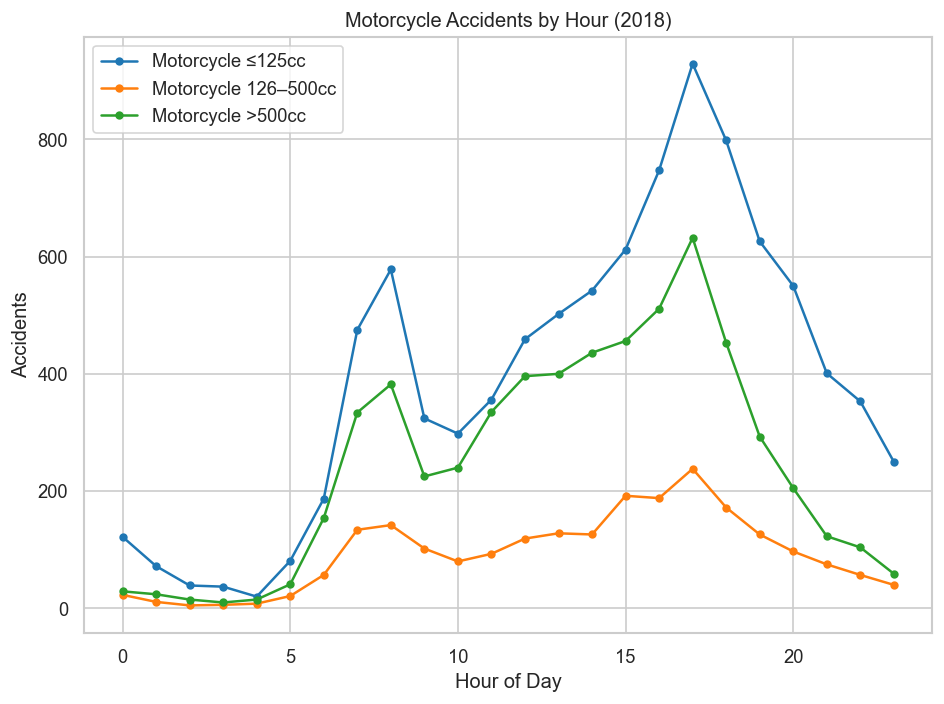

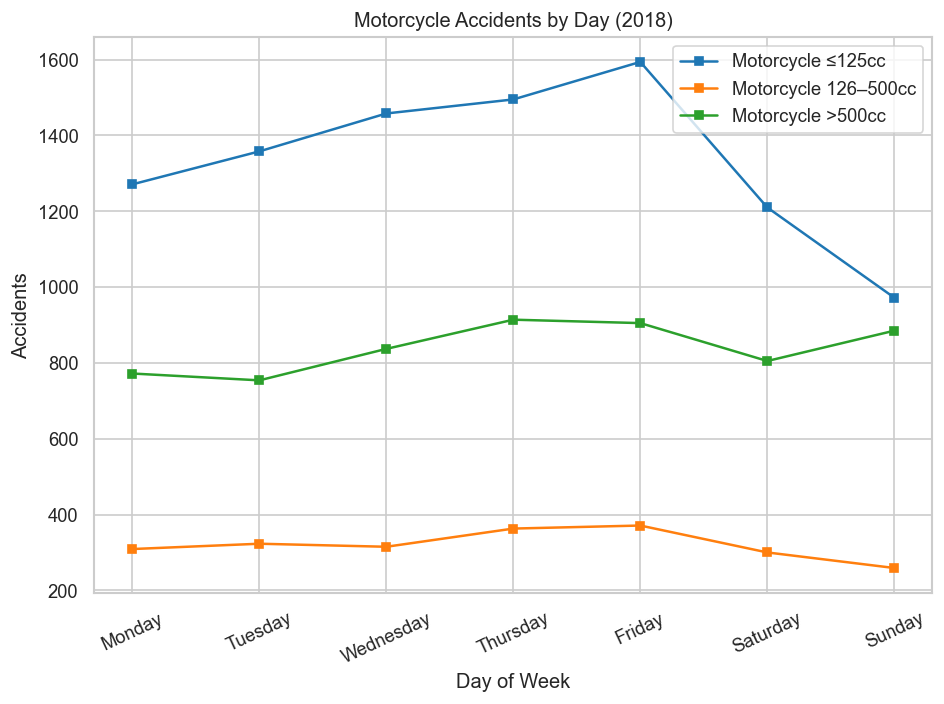

In [10]:
# --- 1. Hourly Line Plot ---
plt.figure(figsize=(8,6))

for grp in MOTO_GROUP_ORDER:
    sub = moto_acc[moto_acc['moto_group'] == grp]
    h   = sub.groupby('hour').size().reindex(range(24), fill_value=0)

    plt.plot(h.index, h.values,
             marker='o', markersize=4,
             label=grp, color=MOTO_COLOURS[grp])

plt.title('Motorcycle Accidents by Hour (2018)')
plt.xlabel('Hour of Day')
plt.ylabel('Accidents')
plt.legend()

plt.tight_layout()
plt.savefig('task2_motorcycle_hourly.png', bbox_inches='tight')
plt.show()


# --- 2. Daily Line Plot ---
plt.figure(figsize=(8,6))

for grp in MOTO_GROUP_ORDER:
    sub = moto_acc[moto_acc['moto_group'] == grp]
    d   = sub.groupby('day_name').size().reindex(DAY_ORDER, fill_value=0)

    plt.plot(d.index, d.values,
             marker='s', markersize=5,
             label=grp, color=MOTO_COLOURS[grp])

plt.title('Motorcycle Accidents by Day (2018)')
plt.xlabel('Day of Week')
plt.ylabel('Accidents')
plt.xticks(rotation=25)
plt.legend()

plt.tight_layout()
plt.savefig('task2_motorcycle_daily.png', bbox_inches='tight')
plt.show()

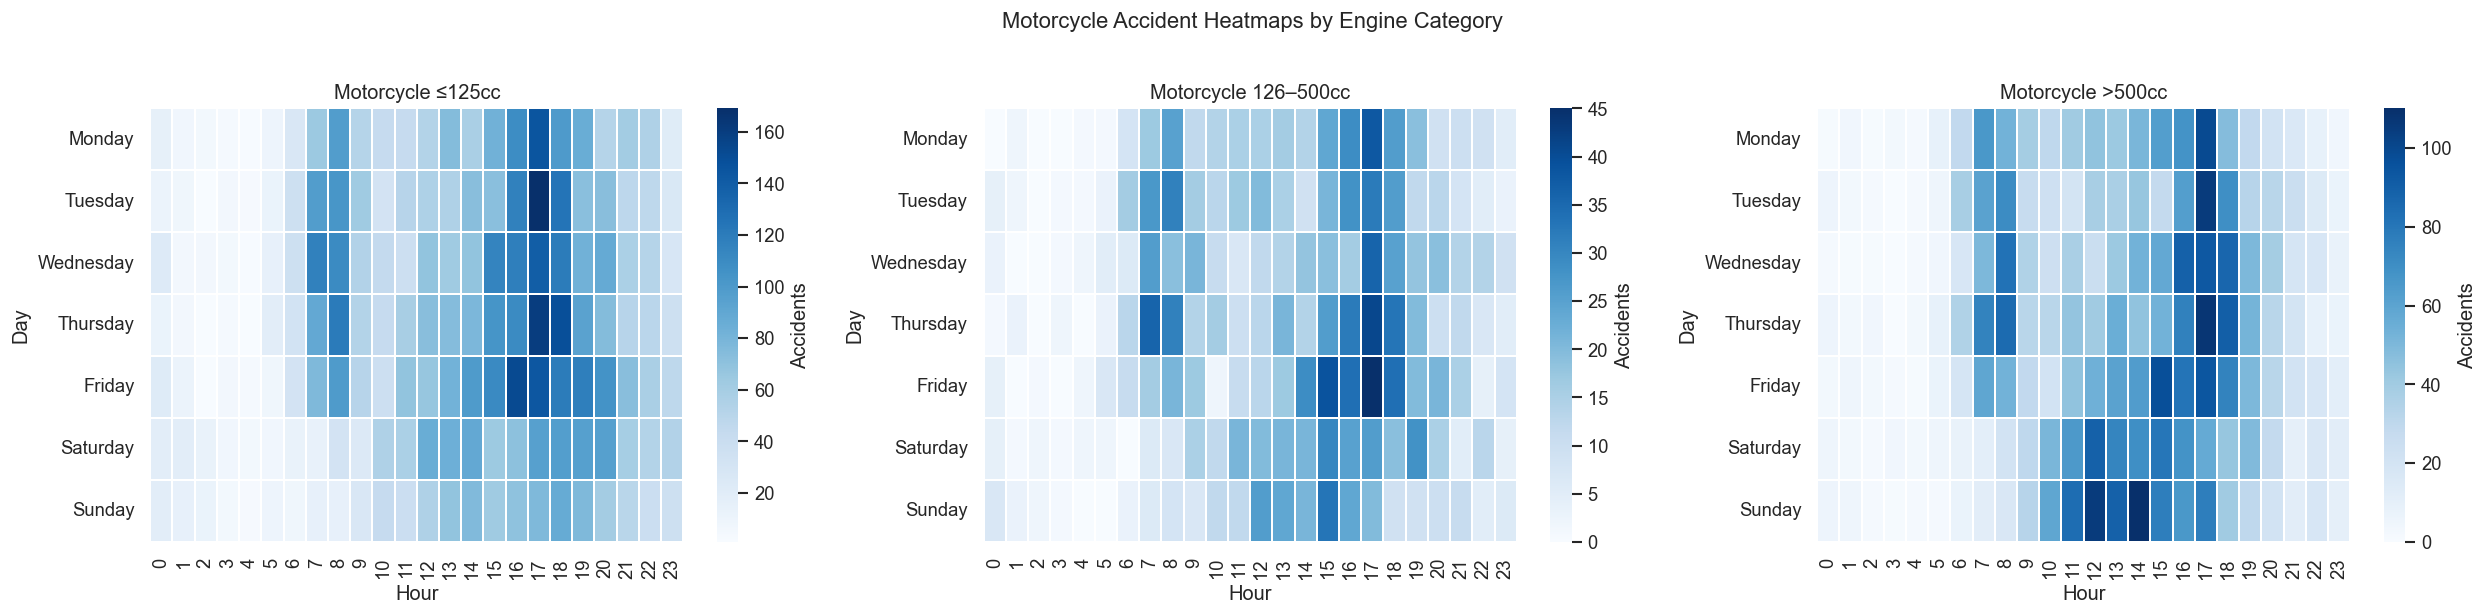

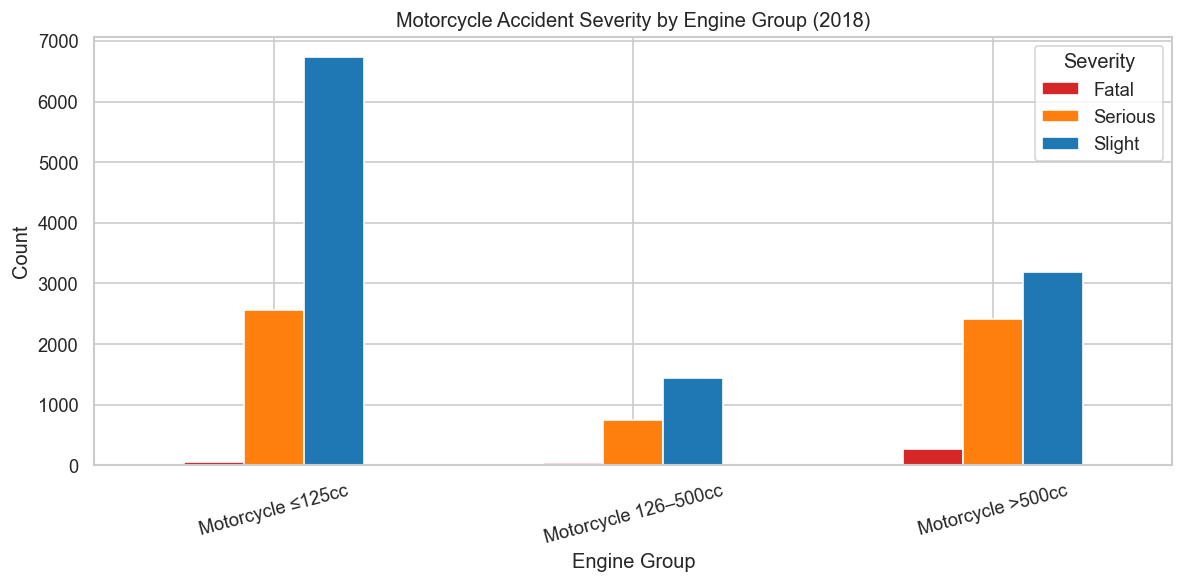

In [11]:
# Per-group heatmaps
fig, axes = plt.subplots(1, 3, figsize=(21, 5))
for ax, grp in zip(axes, MOTO_GROUP_ORDER):
    hm = (moto_acc[moto_acc['moto_group']==grp]
          .groupby(['day_name','hour']).size()
          .unstack(fill_value=0).reindex(DAY_ORDER))
    sns.heatmap(hm, ax=ax, cmap='Blues', linewidths=0.2,
                cbar_kws={'label':'Accidents'})
    ax.set(title=grp, xlabel='Hour', ylabel='Day')
plt.suptitle('Motorcycle Accident Heatmaps by Engine Category', y=1.02)
plt.tight_layout()
plt.savefig('task2_motorcycle_heatmaps.png', bbox_inches='tight')
plt.show()

# Severity per group (STATS20 §3.9)
sev_moto = (moto_acc.groupby(['moto_group','severity_label'])
            .size().unstack(fill_value=0)
            .reindex(MOTO_GROUP_ORDER))
for col in ['Fatal','Serious','Slight']:
    if col not in sev_moto.columns:
        sev_moto[col] = 0
sev_moto[['Fatal','Serious','Slight']].plot(
    kind='bar', figsize=(10,5), color=['#d62728','#ff7f0e','#1f77b4'])
plt.title('Motorcycle Accident Severity by Engine Group (2018)')
plt.xlabel('Engine Group'); plt.ylabel('Count')
plt.xticks(rotation=15)
plt.legend(title='Severity')
plt.tight_layout()
plt.savefig('task2_motorcycle_severity.png', bbox_inches='tight')
plt.show()

=== Motorcycle Counts (2018) ===
moto_group
Motorcycle ≤125cc       9362
Motorcycle 126–500cc    2240
Motorcycle >500cc       5876
Name: count, dtype: int64

=== Motorcycle Percentage Breakdown (2018) ===
moto_group
Motorcycle ≤125cc       53.56
Motorcycle 126–500cc    12.82
Motorcycle >500cc       33.62
Name: count, dtype: float64


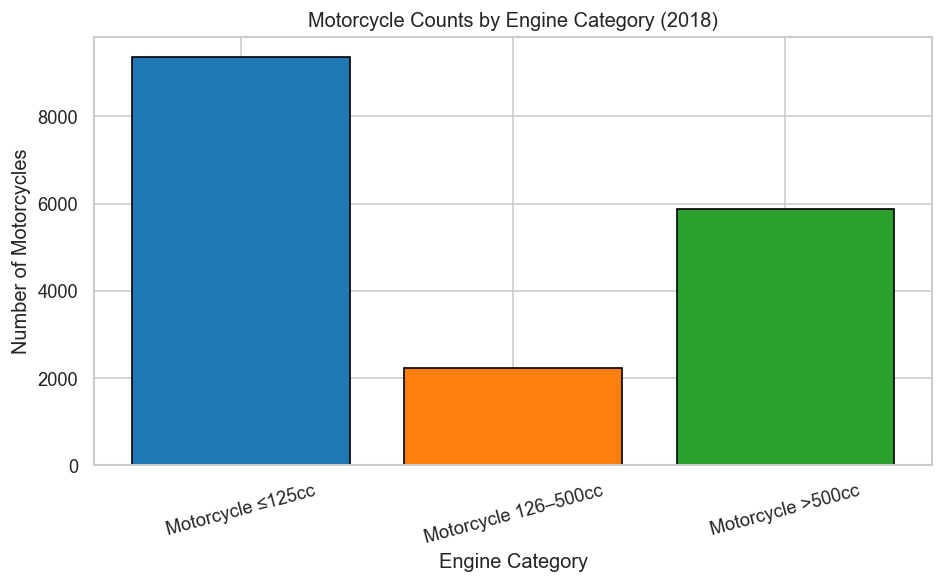

In [12]:

# Count motorcycles in each engine-size group
moto_counts = (
    moto_veh['moto_group']
    .value_counts()
    .reindex(MOTO_GROUP_ORDER)   # ensures correct order: ≤125cc, 126–500cc, >500cc
)

# Percentage breakdown
moto_percent = (moto_counts / moto_counts.sum()) * 100

print("=== Motorcycle Counts (2018) ===")
print(moto_counts)
print("\n=== Motorcycle Percentage Breakdown (2018) ===")
print(moto_percent.round(2))

# -----------------------------
# BAR CHART
# -----------------------------
plt.figure(figsize=(8,5))
plt.bar(moto_counts.index, moto_counts.values, color=['#1f77b4','#ff7f0e','#2ca02c'], edgecolor='black')

plt.title("Motorcycle Counts by Engine Category (2018)")
plt.xlabel("Engine Category")
plt.ylabel("Number of Motorcycles")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


## CHI-SQUARE Test to Identify Significant Motorcycle Accident Factors

In [13]:
# -----------------------------
# 1. FILTER MOTORCYCLE DATA
# -----------------------------
veh_2018 = veh_all[veh_all['accident_year'] == 2018].copy()
veh_2018['vehicle_type_label'] = veh_2018['vehicle_type'].map(VEHICLE_TYPE)

# Keep only motorcycles
moto_veh = veh_2018[veh_2018['vehicle_type'].isin(MOTO_GROUP_MAP.keys())].copy()
moto_veh['moto_group'] = moto_veh['vehicle_type'].map(MOTO_GROUP_MAP)

# Merge with accident-level context
moto_acc = moto_veh.merge(
    acc_2018[
        [
            'accident_index', 'hour', 'day_name', 'severity_label',
            'light_label', 'weather_label', 'urban_rural_label', 
            'road_type_label', 'road_class_label',  'junction_label', 'junction_control_label', 'speed_limit'
        ]
    ],
    on='accident_index',
    how='inner'
)

# -----------------------------
# 2. CHI-SQUARE TESTS TO FIND SIGNIFICANT FACTORS
# -----------------------------
def chi_square_by_group(df, feature):
    """
    Runs chi-square test to see if distribution of a feature differs
    significantly across motorcycle engine groups.
    """
    table = pd.crosstab(df['moto_group'], df[feature])
    chi2, p, dof, expected = chi2_contingency(table)
    return table, p

# Features to test
features = [
    'hour', 'day_name', 'light_label', 'weather_label',
    'urban_rural_label', 'road_type_label',  'road_class_label', 'junction_label','junction_control_label'
]

results = {}

for f in features:
    table, p = chi_square_by_group(moto_acc, f)
    results[f] = {'table': table, 'p_value': p}

# -----------------------------
# 3. DISPLAY SIGNIFICANT FACTORS
# -----------------------------
print("\n=== SIGNIFICANT DIFFERENCES BETWEEN MOTORCYCLE GROUPS ===\n")
for f, res in results.items():
    if res['p_value'] < 0.05:
        print(f"Feature: {f}  -->  Significant difference (p={res['p_value']:.5f})")
        print(res['table'])
        print("\n")

# -----------------------------
# 4. FIND OVER-REPRESENTED CONDITIONS PER GROUP
# -----------------------------
def overrepresented(df, feature):
    """
    Computes percentage distribution of a feature per motorcycle group.
    Helps identify which conditions are more common for each engine size.
    """
    return (
        df.groupby('moto_group')[feature]
        .value_counts(normalize=True)
        .rename('proportion')
        .mul(100)
        .reset_index()
        .sort_values(['moto_group', 'proportion'], ascending=[True, False])
    )

overrep_results = {}

for f in features:
    overrep_results[f] = overrepresented(moto_acc, f)

# Example: show top 5 overrepresented conditions for each feature
for f in features:
    print(f"\n=== Overrepresented Conditions for {f} ===")
    print(overrep_results[f].groupby('moto_group').head(5))



=== SIGNIFICANT DIFFERENCES BETWEEN MOTORCYCLE GROUPS ===

Feature: hour  -->  Significant difference (p=0.00000)
hour                   0   1   2   3   4   5    6    7    8    9   ...   14  \
moto_group                                                         ...        
Motorcycle 126–500cc   23  11   5   6   8  21   57  134  142  102  ...  126   
Motorcycle >500cc      29  24  15  10  15  41  154  334  382  225  ...  436   
Motorcycle ≤125cc     122  72  39  37  20  81  187  475  578  324  ...  542   

hour                   15   16   17   18   19   20   21   22   23  
moto_group                                                         
Motorcycle 126–500cc  192  188  238  172  126   97   75   57   40  
Motorcycle >500cc     456  511  632  453  293  205  123  104   59  
Motorcycle ≤125cc     612  747  929  798  626  550  401  353  250  

[3 rows x 24 columns]


Feature: day_name  -->  Significant difference (p=0.00000)
day_name              Friday  Monday  Saturday  Sunday  Thursday 

---
## Section 4 – Task 3: Pedestrian Accident Patterns (2018)

- Pedestrians: **casualty_class == 3** (STATS20 §3.6)
- Light conditions: **STATS20 §1.21** (1=Daylight, 4–7=various darkness states)
- Pedestrian location: **STATS20 §3.10**
- Pedestrian movement: **STATS20 §3.11**

In [14]:
cas_2018 = cas_all[cas_all['accident_year'] == 2018].copy()
cas_2018['casualty_class_label']    = cas_2018['casualty_class'].map(CASUALTY_CLASS)
cas_2018['casualty_severity_label'] = cas_2018['casualty_severity'].map(CASUALTY_SEVERITY)
cas_2018['ped_location_label']      = cas_2018['pedestrian_location'].map(PED_LOCATION)
cas_2018['ped_movement_label']      = cas_2018['pedestrian_movement'].map(PED_MOVEMENT)

# casualty_class == 3  
ped_cas = cas_2018[cas_2018['casualty_class'] == 3].copy()

ped_acc = ped_cas.merge(
    acc_2018[['accident_index','hour','day_name','severity_label',
               'light_label','urban_rural_label','weather_label',
               'road_type_label','junction_label']],
    on='accident_index', how='inner'
)
print(f'Pedestrian casualty records (2018): {len(ped_acc):,}')

Pedestrian casualty records (2018): 22,424


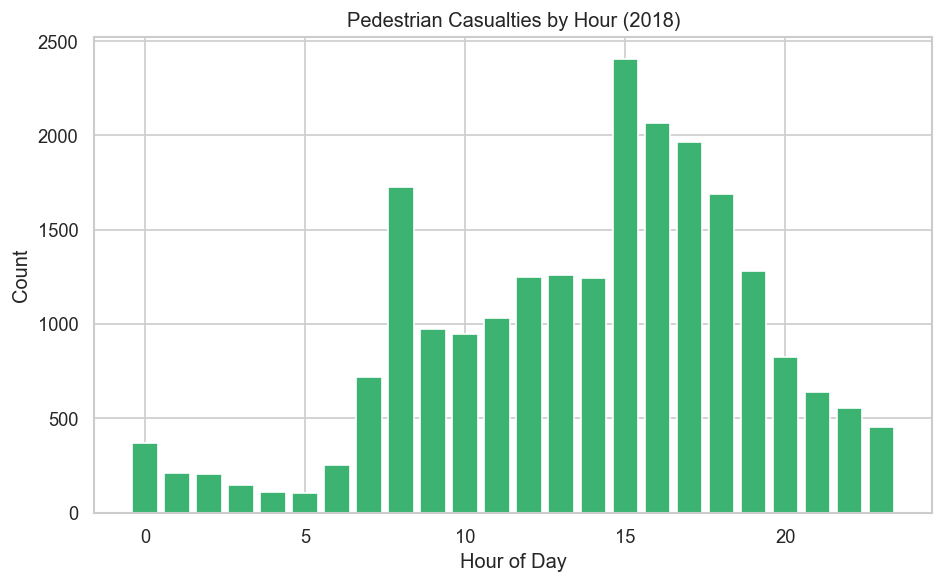

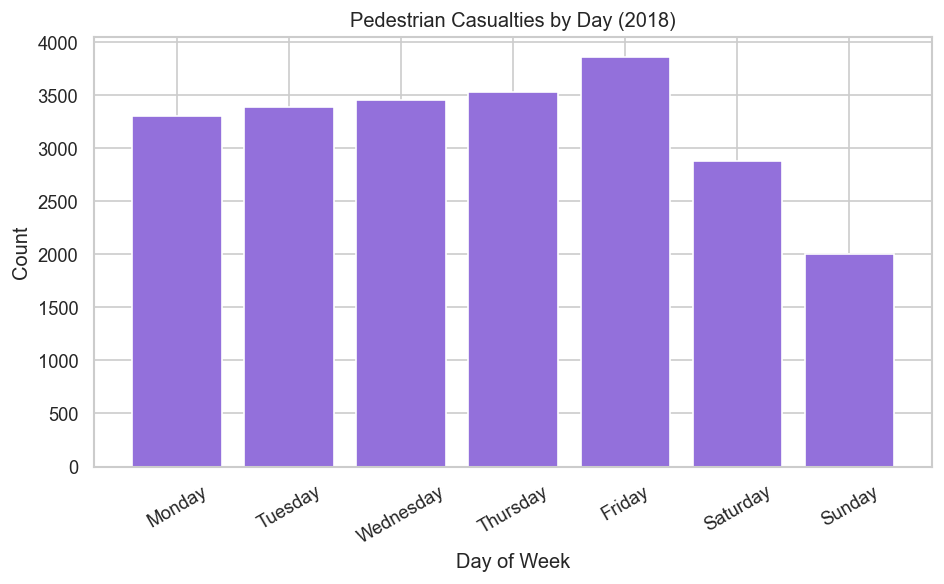

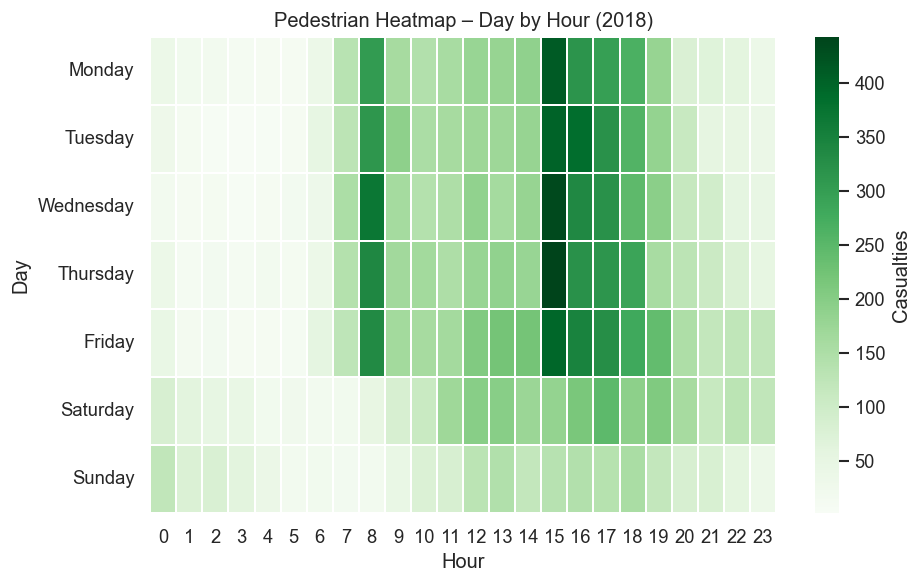

In [15]:
# --- Data preparation (unchanged) ---
ped_hourly = ped_acc.groupby('hour').size().reindex(range(24), fill_value=0)
ped_daily  = ped_acc.groupby('day_name').size().reindex(DAY_ORDER, fill_value=0)
ped_heat   = (ped_acc.groupby(['day_name','hour']).size()
              .unstack(fill_value=0).reindex(DAY_ORDER))


# --- 1. Hourly Bar Chart ---
plt.figure(figsize=(8,5))
plt.bar(ped_hourly.index, ped_hourly.values,
        color='mediumseagreen', edgecolor='white')
plt.title('Pedestrian Casualties by Hour (2018)')
plt.xlabel('Hour of Day')
plt.ylabel('Count')

plt.tight_layout()
plt.savefig('task3_pedestrian_hourly.png', bbox_inches='tight')
plt.show()


# --- 2. Daily Bar Chart ---
plt.figure(figsize=(8,5))
plt.bar(ped_daily.index, ped_daily.values,
        color='mediumpurple', edgecolor='white')
plt.title('Pedestrian Casualties by Day (2018)')
plt.xlabel('Day of Week')
plt.ylabel('Count')
plt.xticks(rotation=30)

plt.tight_layout()
plt.savefig('task3_pedestrian_daily.png', bbox_inches='tight')
plt.show()


# --- 3. Heatmap ---
plt.figure(figsize=(8,5))
sns.heatmap(ped_heat, cmap='Greens', linewidths=0.2,
            cbar_kws={'label':'Casualties'})
plt.title('Pedestrian Heatmap – Day by Hour (2018)')
plt.xlabel('Hour')
plt.ylabel('Day')

plt.tight_layout()
plt.savefig('task3_pedestrian_heatmap.png', bbox_inches='tight')
plt.show()

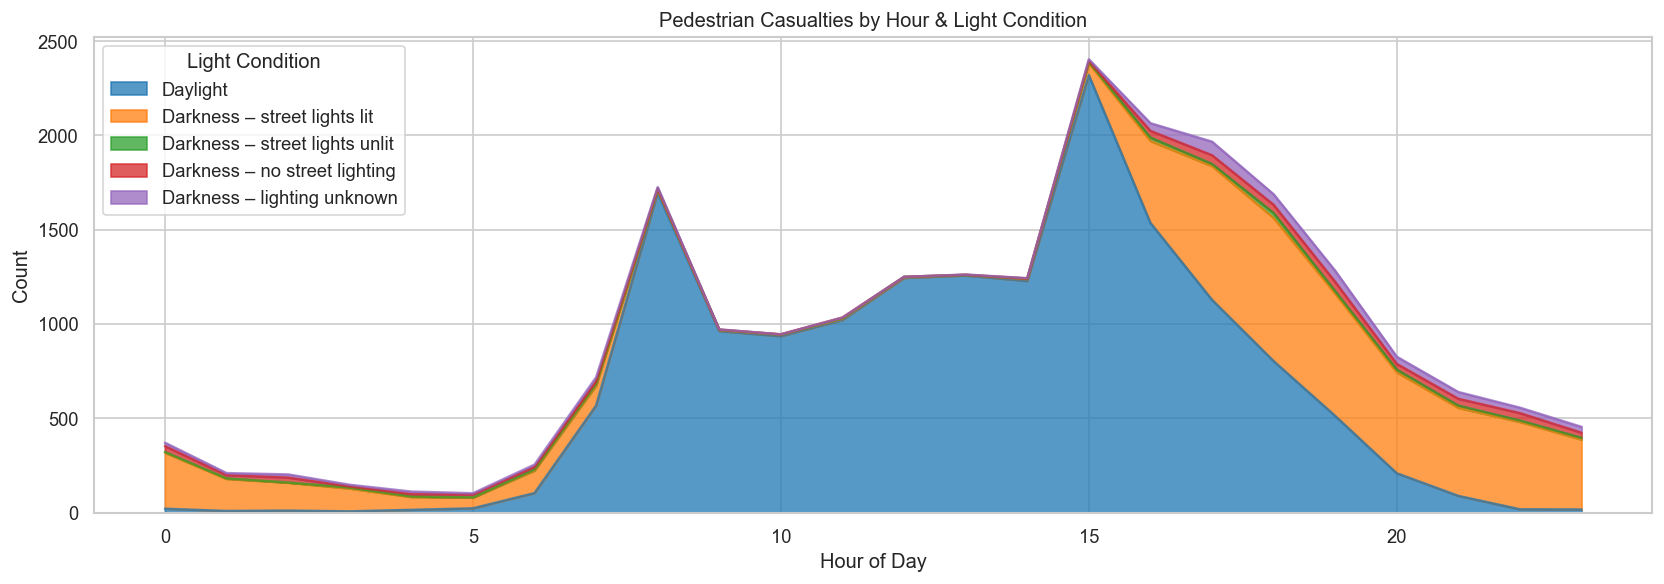

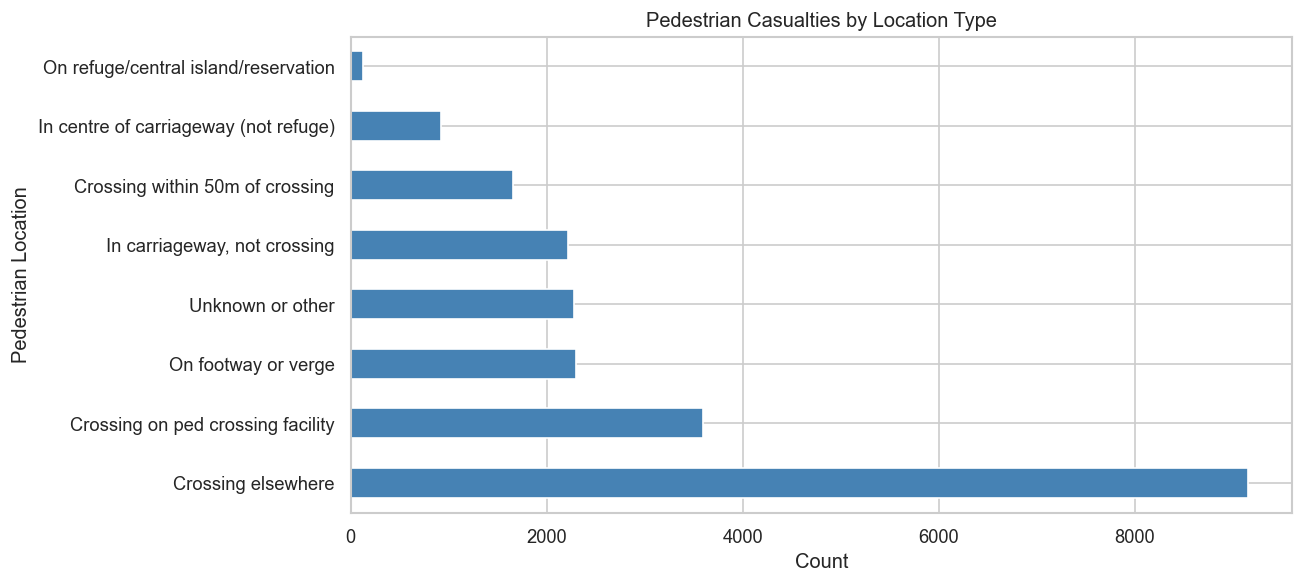

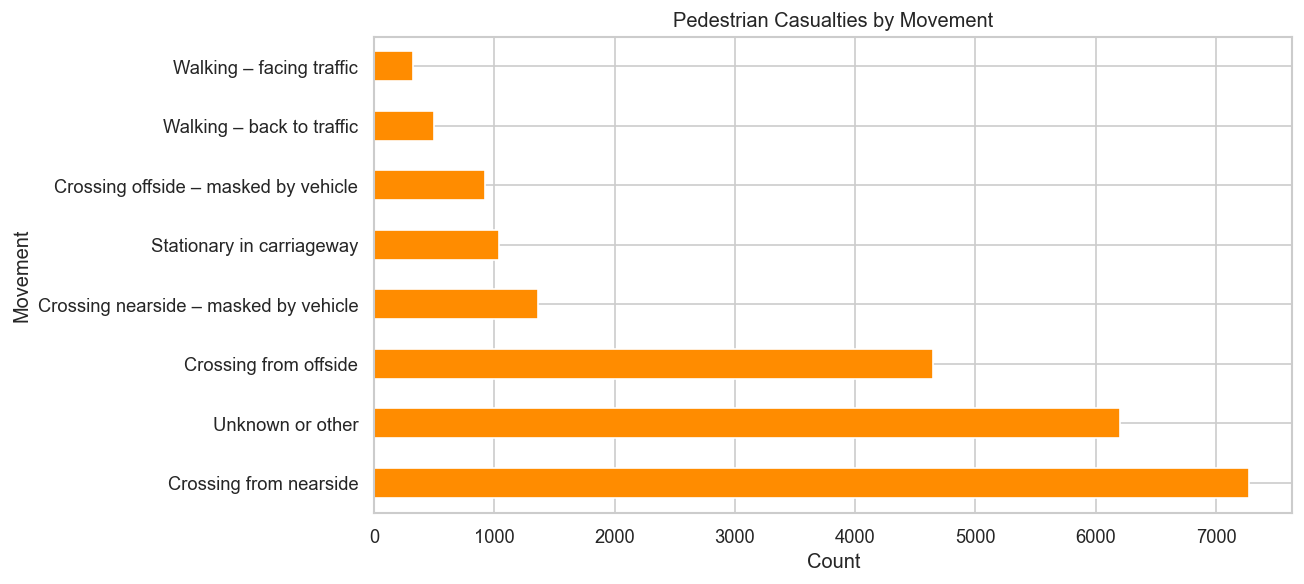

In [16]:
# Stacked area: hour × light condition (STATS20 §1.21)
light_pivot = ped_acc.groupby(['hour','light_label']).size().unstack(fill_value=0)
# Column order follows STATS20 §1.21 code order: 1,4,5,6,7
light_col_order = [LIGHT_CONDITIONS[k] for k in sorted(LIGHT_CONDITIONS)
                   if LIGHT_CONDITIONS[k] in light_pivot.columns]
light_pivot = light_pivot.reindex(columns=light_col_order, fill_value=0)

light_pivot.plot(kind='area', stacked=True, figsize=(14,5), alpha=0.75)
plt.title('Pedestrian Casualties by Hour & Light Condition')
plt.xlabel('Hour of Day'); plt.ylabel('Count')
plt.legend(title='Light Condition', loc='upper left')
plt.tight_layout()
plt.savefig('task3_pedestrian_light.png', bbox_inches='tight')
plt.show()

# Pedestrian location breakdown (STATS20 §3.10)
loc_counts = ped_acc['ped_location_label'].value_counts().head(8)
loc_counts.plot(kind='barh', figsize=(11,5), color='steelblue')
plt.title('Pedestrian Casualties by Location Type')
plt.xlabel('Count'); plt.ylabel('Pedestrian Location')
plt.tight_layout()
plt.savefig('task3_pedestrian_location.png', bbox_inches='tight')
plt.show()

# Pedestrian movement breakdown (STATS20 §3.11)
mov_counts = ped_acc['ped_movement_label'].value_counts().head(8)
mov_counts.plot(kind='barh', figsize=(11,5), color='darkorange')
plt.title('Pedestrian Casualties by Movement')
plt.xlabel('Count'); plt.ylabel('Movement')
plt.tight_layout()
plt.savefig('task3_pedestrian_movement.png', bbox_inches='tight')
plt.show()

## CHI-SQUARE Test To Identify Significant Pedestrian Casualty Factors

In [17]:
# ---------------------------------------------------------
# 1. FILTER PEDESTRIAN CASUALTIES AND MERGE WITH ACCIDENT DATA
# ---------------------------------------------------------

cas_2018 = cas_all[cas_all['accident_year'] == 2018].copy()
cas_2018['casualty_class_label'] = cas_2018['casualty_class'].map(CASUALTY_CLASS)
cas_2018['ped_location_label'] = cas_2018['pedestrian_location'].map(PED_LOCATION)
cas_2018['ped_movement_label'] = cas_2018['pedestrian_movement'].map(PED_MOVEMENT)



# Keep only pedestrians (STATS20 §3.6)
ped_cas = cas_2018[cas_2018['casualty_class'] == 3].copy()

# Merge with accident-level context
ped_acc = ped_cas.merge(
    acc_2018[
        [
            'accident_index', 'hour', 'day_name', 'severity_label',
            'light_label', 'weather_label', 'urban_rural_label',
            'road_type_label', 'junction_label', 'ped_cross_human_control_label','ped_cross_phys_facility_label'
        ]
    ],
    on='accident_index',
    how='inner'
)

print(f"Pedestrian accidents merged: {len(ped_acc):,}")

# ---------------------------------------------------------
# 2. CHI-SQUARE TESTS TO FIND SIGNIFICANT FACTORS
# ---------------------------------------------------------

def chi_square(df, feature):
    table = pd.crosstab(df[feature], df['hour'])  # hour-based comparison
    chi2, p, dof, expected = chi2_contingency(table)
    return p

features = [
    'light_label', 'weather_label', 'urban_rural_label',
    'road_type_label', 'junction_label', 'ped_movement_label', 'ped_location_label',
    'ped_cross_human_control_label','ped_cross_phys_facility_label'
]

sig_results = {}

for f in features:
    p = chi_square(ped_acc, f)
    sig_results[f] = p

print("\n=== SIGNIFICANT DIFFERENCES BY HOUR (p < 0.05) ===")
for f, p in sig_results.items():
    if p < 0.05:
        print(f"{f}: p = {p:.5f}")

# ---------------------------------------------------------
# 3. OVER-REPRESENTED CONDITIONS BY HOUR GROUPS
# ---------------------------------------------------------

# Create time-of-day bands
ped_acc['time_period'] = pd.cut(
    ped_acc['hour'],
    bins=[-1,5,9,12,16,19,23],
    labels=['Night (0-5)','AM Rush (6-9)','Midday (10-12)',
            'PM Rush (13-16)','Evening (17-19)','Late (20-23)']
)

def overrepresented(df, feature):
    return (
        df.groupby('time_period')[feature]
        .value_counts(normalize=True)
        .rename('proportion')
        .mul(100)
        .reset_index()
        .sort_values(['time_period', 'proportion'], ascending=[True, False])
    )

overrep = {}

for f in features:
    overrep[f] = overrepresented(ped_acc, f)

# Example: show top 5 for each feature
for f in features:
    print(f"\n=== Overrepresented Conditions for {f} ===")
    print(overrep[f].groupby('time_period').head(5))


Pedestrian accidents merged: 22,424

=== SIGNIFICANT DIFFERENCES BY HOUR (p < 0.05) ===
light_label: p = 0.00000
weather_label: p = 0.00000
urban_rural_label: p = 0.00023
road_type_label: p = 0.00000
junction_label: p = 0.00002
ped_movement_label: p = 0.00000
ped_location_label: p = 0.00000
ped_cross_human_control_label: p = 0.00000
ped_cross_phys_facility_label: p = 0.00000

=== Overrepresented Conditions for light_label ===
        time_period                     light_label  proportion
0       Night (0-5)    Darkness – street lights lit   75.460123
1       Night (0-5)   Darkness – no street lighting    9.377739
2       Night (0-5)                        Daylight    7.011394
3       Night (0-5)     Darkness – lighting unknown    6.660824
4       Night (0-5)  Darkness – street lights unlit    1.489921
5     AM Rush (6-9)                        Daylight   90.730643
6     AM Rush (6-9)    Darkness – street lights lit    6.679389
7     AM Rush (6-9)     Darkness – lighting unknown    1.2

---
## Section 5 – Task 4: Apriori Association Rule Mining (2018)

All categorical variables are mapped to human-readable labels via STATS20 dictionaries
before encoding, so rules print as `surface_label=Wet/Damp` not `road_surface_conditions=2`.

In [18]:
apriori_df = acc_2018[[
    'accident_severity','weather_conditions','road_surface_conditions',
    'light_conditions','speed_limit','road_type','urban_or_rural_area',
    'junction_detail','hour'
]].copy().dropna()

# Map all codes to STATS20 labels
apriori_df['severity_label']  = apriori_df['accident_severity'].map(ACCIDENT_SEVERITY)
apriori_df['weather_label']   = apriori_df['weather_conditions'].map(WEATHER)
apriori_df['surface_label']   = apriori_df['road_surface_conditions'].map(ROAD_SURFACE)
apriori_df['light_label']     = apriori_df['light_conditions'].map(LIGHT_CONDITIONS)
apriori_df['road_type_label'] = apriori_df['road_type'].map(ROAD_TYPE)
apriori_df['area_label']      = apriori_df['urban_or_rural_area'].map(URBAN_RURAL)
apriori_df['junction_label']  = apriori_df['junction_detail'].map(JUNCTION_DETAIL)

# Speed limit bin (permanent limit – STATS20 §1.15; normal values 20/30/40/50/60/70)
apriori_df['speed_bin'] = pd.cut(
    apriori_df['speed_limit'],
    bins=[0,30,50,70,200],
    labels=['SpeedLimit_≤30mph','SpeedLimit_31-50mph',
            'SpeedLimit_51-70mph','SpeedLimit_>70mph']
)

apriori_df['time_period'] = pd.cut(
    apriori_df['hour'],
    bins=[-1,5,9,12,16,19,23],
    labels=['Night','AM_Rush','Midday','PM_Rush','Evening','Late_Night']
)

feature_cols = ['severity_label','weather_label','surface_label','light_label',
                'road_type_label','area_label','junction_label',
                'speed_bin','time_period']

transactions = apriori_df[feature_cols].astype(str).apply(
    lambda row: [f'{col}={val}' for col, val in row.items()], axis=1
).tolist()

te       = TransactionEncoder()
te_array = te.fit(transactions).transform(transactions)
df_enc   = pd.DataFrame(te_array, columns=te.columns_)
print(f'Transaction matrix: {df_enc.shape}')

Transaction matrix: (122580, 52)


In [19]:
frequent_itemsets = apriori(df_enc, min_support=0.05, use_colnames=True)
print(f'Frequent itemsets: {len(frequent_itemsets):,}')

rules = association_rules(frequent_itemsets, metric='confidence', min_threshold=0.5)

SEV_LABELS = {'severity_label=Fatal','severity_label=Serious','severity_label=Slight'}
rules['sev_consequent'] = rules['consequents'].apply(
    lambda x: bool(set(x) & SEV_LABELS)
)
sev_rules = rules[rules['sev_consequent']].copy()
sev_rules.sort_values('lift', ascending=False, inplace=True)

print(f'Severity-related rules: {len(sev_rules):,}')
print('\nTop 10 rules by lift:')

top10 = sev_rules[['antecedents','consequents','support','confidence','lift']].head(10).copy()

# Convert frozensets to readable strings
top10['antecedents'] = top10['antecedents'].apply(lambda x: ', '.join(list(x)))
top10['consequents'] = top10['consequents'].apply(lambda x: ', '.join(list(x)))

# Round values for clean display
top10[['support','confidence','lift']] = top10[['support','confidence','lift']].round(3)

# Reset index for clean table look
top10 = top10.reset_index(drop=True)
pd.set_option('display.max_colwidth', None)
display(top10)

Frequent itemsets: 1,615
Severity-related rules: 3,666

Top 10 rules by lift:


,antecedents,consequents,support,confidence,lift
0,"weather_label=Raining, no high winds","severity_label=Slight, area_label=Urban, surface_label=Wet/Damp",0.055,0.524,4.520
1,"weather_label=Raining, no high winds","severity_label=Slight, surface_label=Wet/Damp, speed_bin=SpeedLimit_≤30mph",0.055,0.524,4.481
2,"area_label=Urban, weather_label=Raining, no high winds","severity_label=Slight, surface_label=Wet/Damp",0.055,0.801,4.396
3,"weather_label=Raining, no high winds, speed_bin=SpeedLimit_≤30mph","severity_label=Slight, surface_label=Wet/Damp",0.055,0.798,4.380
4,"weather_label=Raining, no high winds","severity_label=Slight, surface_label=Wet/Damp",0.082,0.783,4.296
5,"road_type_label=Single carriageway, weather_label=Raining, no high winds","severity_label=Slight, surface_label=Wet/Damp",0.056,0.772,4.233
6,"weather_label=Raining, no high winds","severity_label=Slight, road_type_label=Single carriageway, surface_label=Wet/Damp",0.056,0.535,4.159
7,"time_period=Late_Night, area_label=Urban","severity_label=Slight, light_label=Darkness – street lights lit",0.051,0.606,3.804
8,"speed_bin=SpeedLimit_51-70mph, light_label=Daylight, weather_label=Fine, no high winds","surface_label=Dry, area_label=Rural, severity_label=Slight",0.065,0.573,3.399
9,"speed_bin=SpeedLimit_51-70mph, surface_label=Dry","severity_label=Slight, light_label=Daylight, weather_label=Fine, no high winds, area_label=Rural",0.065,0.518,3.378


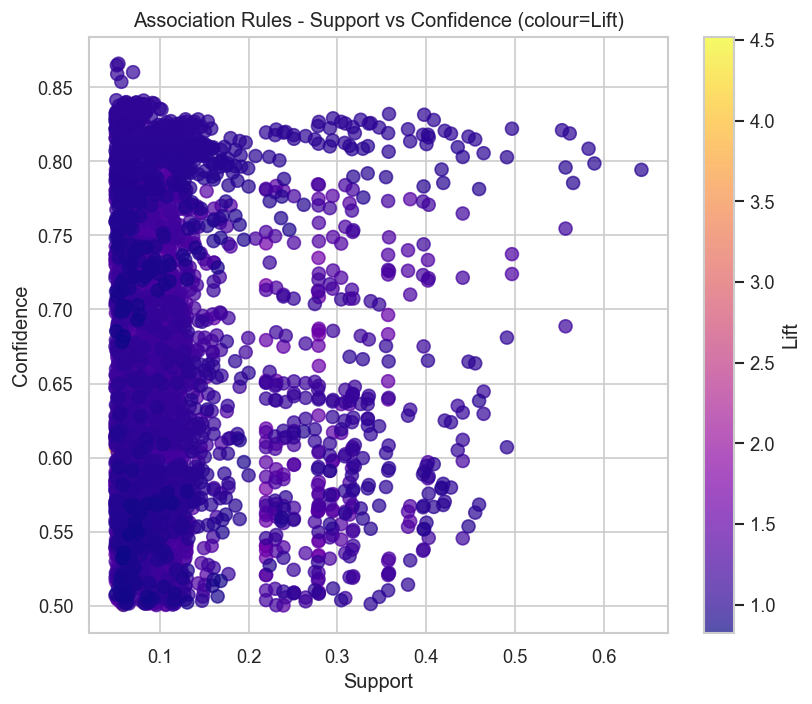

In [20]:
# --- 1. Scatter Plot: Support vs Confidence ---
plt.figure(figsize=(7,6))

sc = plt.scatter(sev_rules['support'], sev_rules['confidence'],
                 c=sev_rules['lift'], cmap='plasma', alpha=0.7, s=60)

plt.colorbar(sc, label='Lift')
plt.title('Association Rules - Support vs Confidence (colour=Lift)')
plt.xlabel('Support')
plt.ylabel('Confidence')

plt.tight_layout()
plt.savefig('task4_rules_scatter.png', bbox_inches='tight')
plt.show()


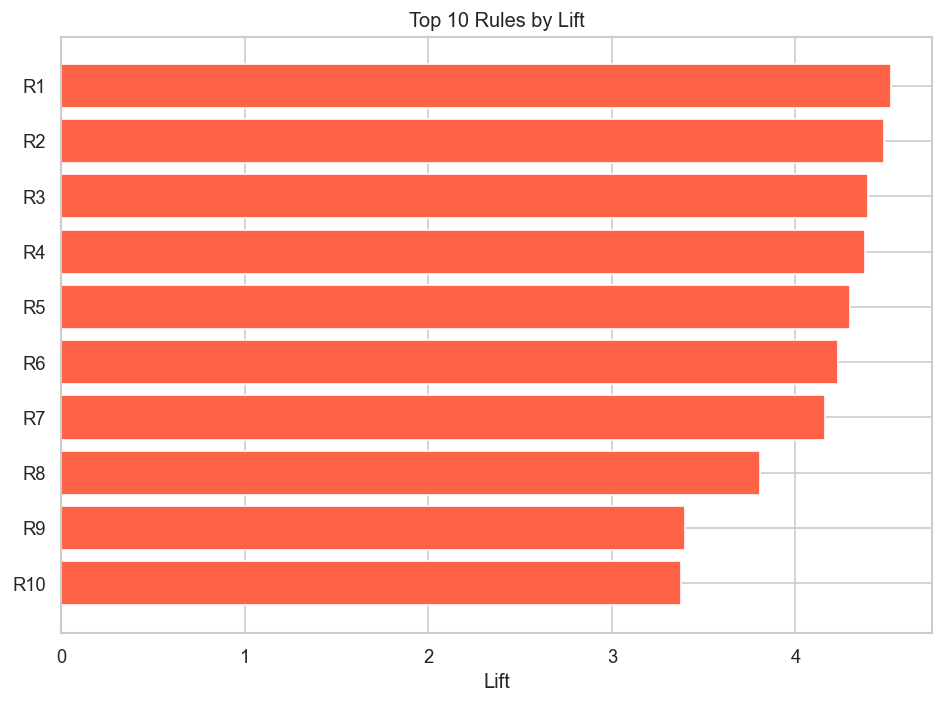

In [21]:
top10 = sev_rules.head(10).copy().reset_index(drop=True)
top10['rule_id'] = [f'R{i+1}' for i in range(len(top10))]

plt.figure(figsize=(8,6))
plt.barh(top10['rule_id'], top10['lift'], color='tomato')
plt.xlabel('Lift')
plt.title('Top 10 Rules by Lift')
plt.gca().invert_yaxis()

plt.tight_layout()
plt.savefig('task4_rules_clean.png', bbox_inches='tight')
plt.show()

---
## Section 6 – Task 5: Clustering in West Yorkshire (2018)

West Yorkshire = police_force **13** (STATS20 Annex 6).  
Two algorithms applied: **KMeans** (with elbow + silhouette for k selection)
and **DBSCAN** (density-based spatial clustering for hotspot identification).

In [22]:
wy_acc = acc_2018[
    acc_2018['police_force'] == WY_POLICE_CODE  # 13 = West Yorkshire
].dropna(subset=['latitude','longitude']).copy()

print(f'West Yorkshire 2018 accidents: {len(wy_acc):,}')
print(f'Force label: {wy_acc["police_force_label"].unique()}')

West Yorkshire 2018 accidents: 4,132
Force label: ['West Yorkshire']


In [23]:
# Feature matrix: spatial + STATS20-coded contextual attributes
cluster_features = ['latitude','longitude','accident_severity',
                    'hour','speed_limit','light_conditions',
                    'road_type','urban_or_rural_area']

X_raw    = wy_acc[cluster_features].dropna().copy()
wy_clean = wy_acc.loc[X_raw.index].copy()

scaler   = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)
print(f'Clustering input shape: {X_scaled.shape}')

Clustering input shape: (4132, 8)


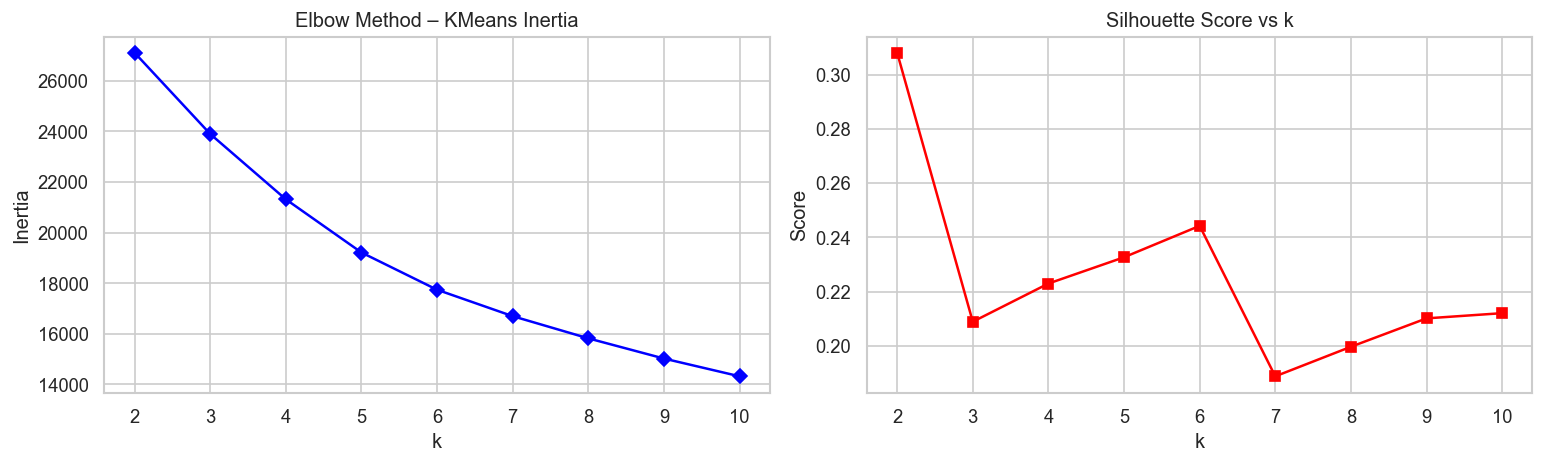

Optimal k (silhouette): 2


In [24]:
inertias, sil_scores = [], []
K_range = range(2, 11)

for k in K_range:
    km  = KMeans(n_clusters=k, random_state=42, n_init=10)
    lbl = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(
        X_scaled, lbl,
        sample_size=min(5000, len(X_scaled)), random_state=42
    ))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(K_range, inertias, 'bD-')
axes[0].set(title='Elbow Method – KMeans Inertia', xlabel='k', ylabel='Inertia')
axes[1].plot(K_range, sil_scores, 'rs-')
axes[1].set(title='Silhouette Score vs k', xlabel='k', ylabel='Score')
plt.tight_layout()
plt.savefig('task5_elbow_silhouette.png', bbox_inches='tight')
plt.show()

best_k = list(K_range)[np.argmax(sil_scores)]
print(f'Optimal k (silhouette): {best_k}')

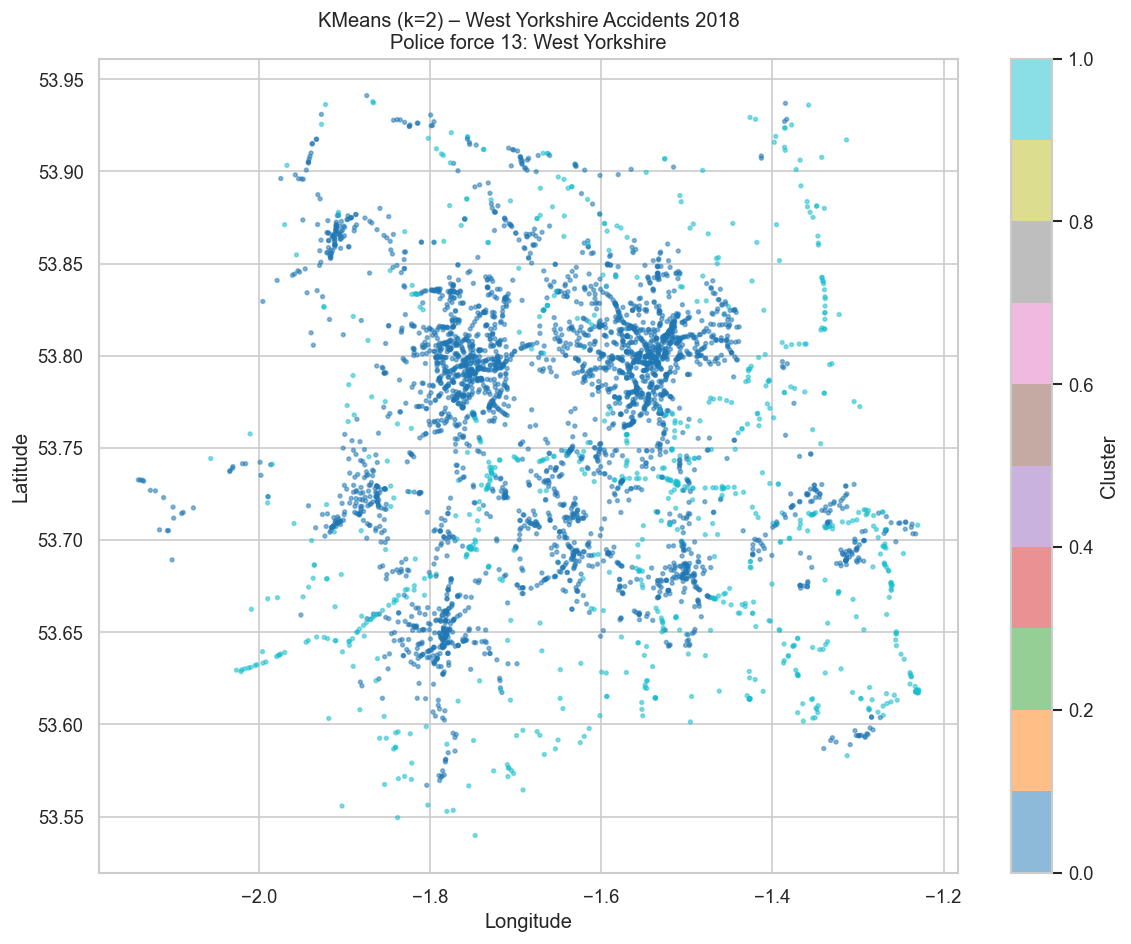

=== KMeans Cluster Profiles ===
            count  fatal_pct  serious_pct  avg_speed_limit  avg_hour  centroid_lat  centroid_lon
cluster_km                                                                                      
0            3314       1.12        17.47            30.69     13.95         53.77         -1.66
1             818       3.18        19.56            51.70     13.22         53.72         -1.57


In [25]:
km_final = KMeans(n_clusters=best_k, random_state=42, n_init=10)
wy_clean['cluster_km'] = km_final.fit_predict(X_scaled)

fig, ax = plt.subplots(figsize=(10, 8))
sc = ax.scatter(wy_clean['longitude'], wy_clean['latitude'],
                c=wy_clean['cluster_km'], cmap='tab10', s=5, alpha=0.5)
plt.colorbar(sc, ax=ax, label='Cluster')
ax.set(title=(f'KMeans (k={best_k}) – West Yorkshire Accidents 2018\n'
              f'Police force {WY_POLICE_CODE}: {POLICE_FORCE[WY_POLICE_CODE]}'),
       xlabel='Longitude', ylabel='Latitude')
plt.tight_layout()
plt.savefig('task5_kmeans_geo.png', bbox_inches='tight')
plt.show()

# Cluster profile with STATS20-coded severity breakdowns
wy_clean['severity_label'] = wy_clean['accident_severity'].map(ACCIDENT_SEVERITY)
profile = wy_clean.groupby('cluster_km').agg(
    count           = ('accident_index','count'),
    fatal_pct       = ('accident_severity', lambda x: (x==1).mean()*100),
    serious_pct     = ('accident_severity', lambda x: (x==2).mean()*100),
    avg_speed_limit = ('speed_limit','mean'),
    avg_hour        = ('hour','mean'),
    centroid_lat    = ('latitude','mean'),
    centroid_lon    = ('longitude','mean')
).round(2)
print('=== KMeans Cluster Profiles ===')
print(profile.to_string())

DBSCAN clusters: 12  |  Noise: 92.7%


C:\Users\twuma\AppData\Local\Temp\ipykernel_24668\1583731122.py:12: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap20 = plt.cm.get_cmap('tab20', n_db + 1)


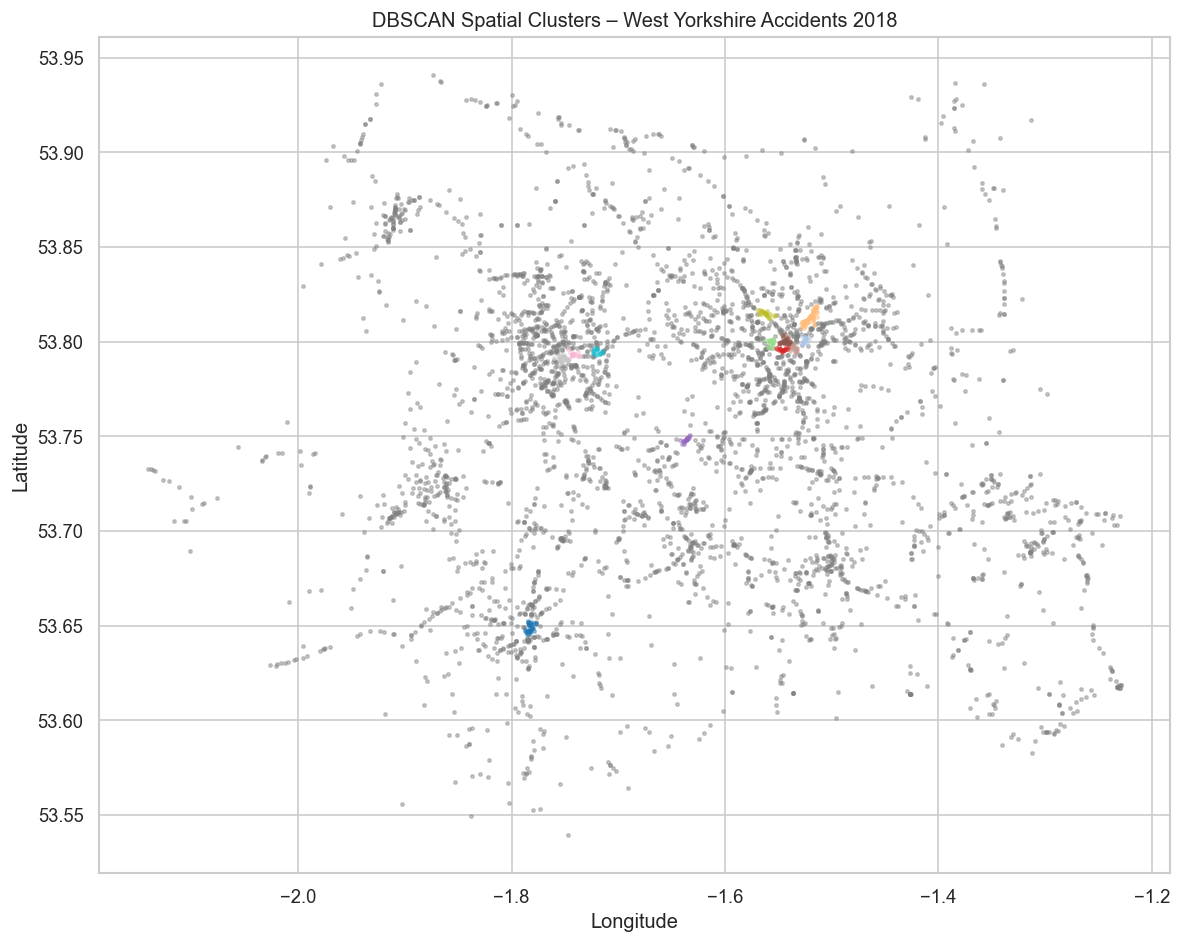

<Figure size 1440x600 with 0 Axes>

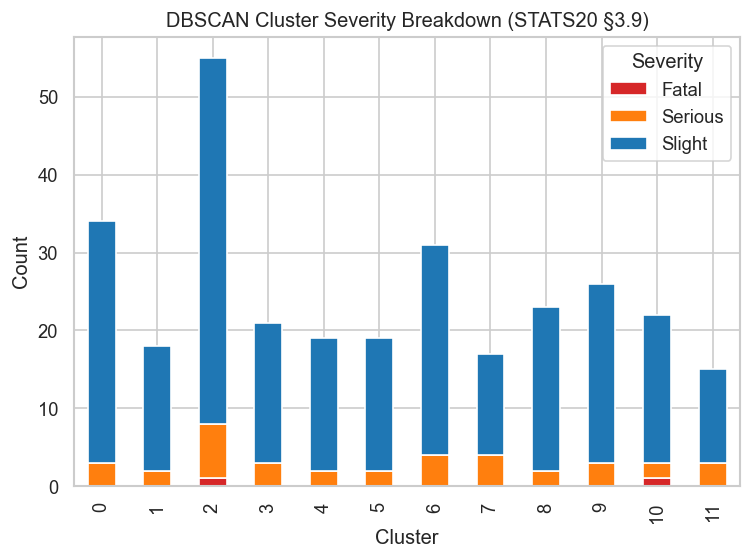

In [26]:
# DBSCAN – density-based spatial clustering
X_geo = StandardScaler().fit_transform(wy_clean[['latitude','longitude']])
db    = DBSCAN(eps=0.03, min_samples=15)
wy_clean['cluster_dbscan'] = db.fit_predict(X_geo)

n_db      = len(set(wy_clean['cluster_dbscan'])) - (1 if -1 in wy_clean['cluster_dbscan'].values else 0)
noise_pct = (wy_clean['cluster_dbscan'] == -1).mean() * 100
print(f'DBSCAN clusters: {n_db}  |  Noise: {noise_pct:.1f}%')

# ---- Plot 1: Spatial clusters ----
plt.figure(figsize=(10, 8))
cmap20 = plt.cm.get_cmap('tab20', n_db + 1)

for label in sorted(wy_clean['cluster_dbscan'].unique()):
    sub  = wy_clean[wy_clean['cluster_dbscan'] == label]
    col  = 'grey' if label == -1 else cmap20(label)
    name = 'Noise' if label == -1 else f'Cluster {label}'
    plt.scatter(sub['longitude'], sub['latitude'],
                c=[col], s=4, alpha=0.4, label=name)

plt.title('DBSCAN Spatial Clusters – West Yorkshire Accidents 2018')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.tight_layout()
plt.savefig('task5_dbscan_geo.png', bbox_inches='tight')
plt.show()

# ---- Plot 2: Severity per cluster ----
plt.figure(figsize=(12, 5))
db_non_noise = wy_clean[wy_clean['cluster_dbscan'] != -1].copy()
db_sev = (db_non_noise.groupby(['cluster_dbscan','severity_label'])
          .size().unstack(fill_value=0))

db_sev.plot(kind='bar', stacked=True,
            color=['#d62728','#ff7f0e','#1f77b4'])

plt.title('DBSCAN Cluster Severity Breakdown (STATS20 §3.9)')
plt.xlabel('Cluster')
plt.ylabel('Count')
plt.legend(title='Severity')
plt.tight_layout()
plt.savefig('task5_dbscan_severity.png', bbox_inches='tight')
plt.show()

---
## Section 7 - Task 6: Time Series Forecasting by Police Area (2017–2019)

Three policing areas selected using **STATS20 Annex 6** police force codes:

| Code | Force |
|---|---|
| **01** | Metropolitan Police |
| **13** | West Yorkshire |
| **43** | Thames Valley |

Training: 2017-2018 (weekly counts). Test: 2019 (weekly counts). Model: **SARIMA** with seasonal period m=52 (annual weekly cycle).

In [27]:
acc_multi = acc_all[acc_all['year'].isin([2017,2018,2019])].copy()
print('Records per year:')
print(acc_multi['year'].value_counts().sort_index())
print('\nForce record counts (STATS20 Annex 6 verification):')
for code, name in POLICE_AREAS.items():
    n = (acc_multi['police_force'] == code).sum()
    print(f'  Code {code:02d} – {name}: {n:,} records')

Records per year:
year
2017    129953
2018    122580
2019    117508
Name: count, dtype: int64

Force record counts (STATS20 Annex 6 verification):
  Code 01 – Metropolitan Police: 77,186 records
  Code 13 – West Yorkshire: 12,111 records
  Code 43 – Thames Valley: 11,525 records


In [28]:
def build_weekly_series(df: pd.DataFrame, code: int) -> pd.Series:
    """Weekly accident count for a given police force code."""
    s = (df[df['police_force'] == code]
         .set_index('date').sort_index()
         .resample('W').size())
    s.name = 'accident_count'
    return s

def adf_report(series: pd.Series, name: str = '') -> bool:
    """Augmented Dickey-Fuller test. Returns True if stationary (p<0.05)."""
    r = adfuller(series.dropna())
    stat = r[1] < 0.05
    print(f'{name:30s}  ADF={r[0]:7.3f}  p={r[1]:.4f}  '
          f'{"STATIONARY" if stat else "NON-STATIONARY"}')
    return stat

def fit_sarima(train: pd.Series, test: pd.Series,
               name: str, seasonal_order=(1,1,1,52)) -> dict:
    """
    Grid-search SARIMA(p,1,q)(P,D,Q,52): p,q ∈ {0,1,2}.
    Returns dict with model, forecast, RMSE, MAPE.
    """
    best_aic, best_order = np.inf, (1,1,1)
    for p, q in itertools.product(range(3), range(3)):
        try:
            m = SARIMAX(train, order=(p,1,q),
                        seasonal_order=seasonal_order,
                        enforce_stationarity=False,
                        enforce_invertibility=False).fit(disp=False)
            if m.aic < best_aic:
                best_aic, best_order = m.aic, (p,1,q)
        except Exception:
            continue
    print(f'  [{name}] Best order: {best_order}, AIC: {best_aic:.2f}')

    final = SARIMAX(train, order=best_order,
                    seasonal_order=seasonal_order,
                    enforce_stationarity=False,
                    enforce_invertibility=False).fit(disp=False)
    fc = final.forecast(steps=len(test))
    fc.index = test.index

    rmse = np.sqrt(mean_squared_error(test, fc))
    mape = mean_absolute_percentage_error(test, fc) * 100
    return {'model':final,'forecast':fc,'rmse':rmse,'mape':mape,'order':best_order}

print('Helper functions defined.')

Helper functions defined.



── Metropolitan Police (STATS20 Annex 6 code 01) ──
Metropolitan Police             ADF= -7.999  p=0.0000  STATIONARY
  [Metropolitan Police] Best order: (0, 1, 0), AIC: 6.00


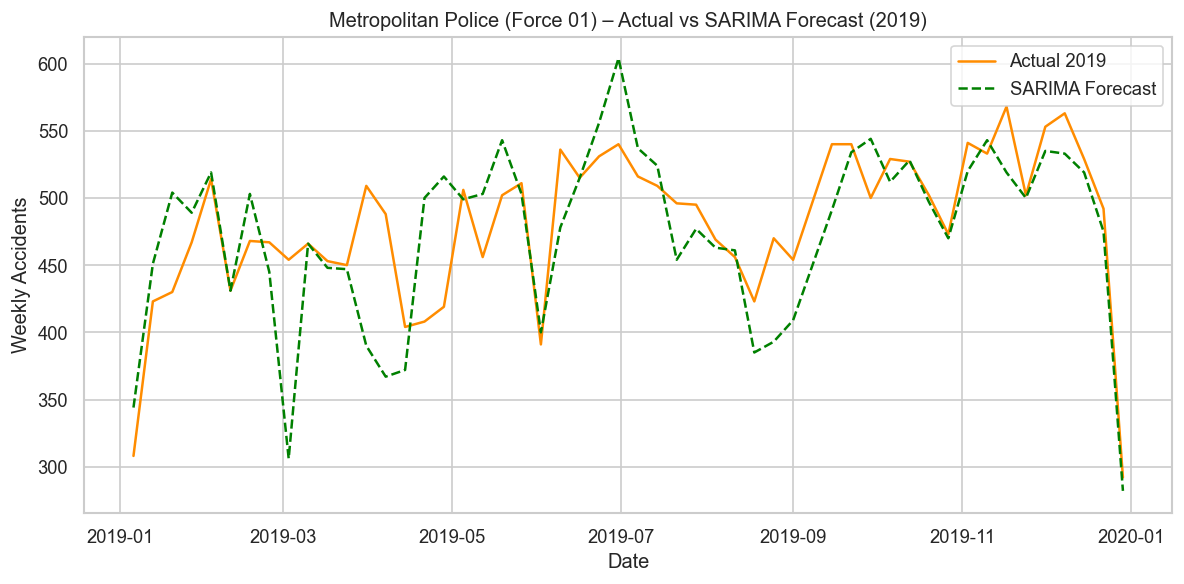

  RMSE=47.10  MAPE=6.98%

── West Yorkshire (STATS20 Annex 6 code 13) ──
West Yorkshire                  ADF= -8.416  p=0.0000  STATIONARY
  [West Yorkshire] Best order: (0, 1, 0), AIC: 6.00


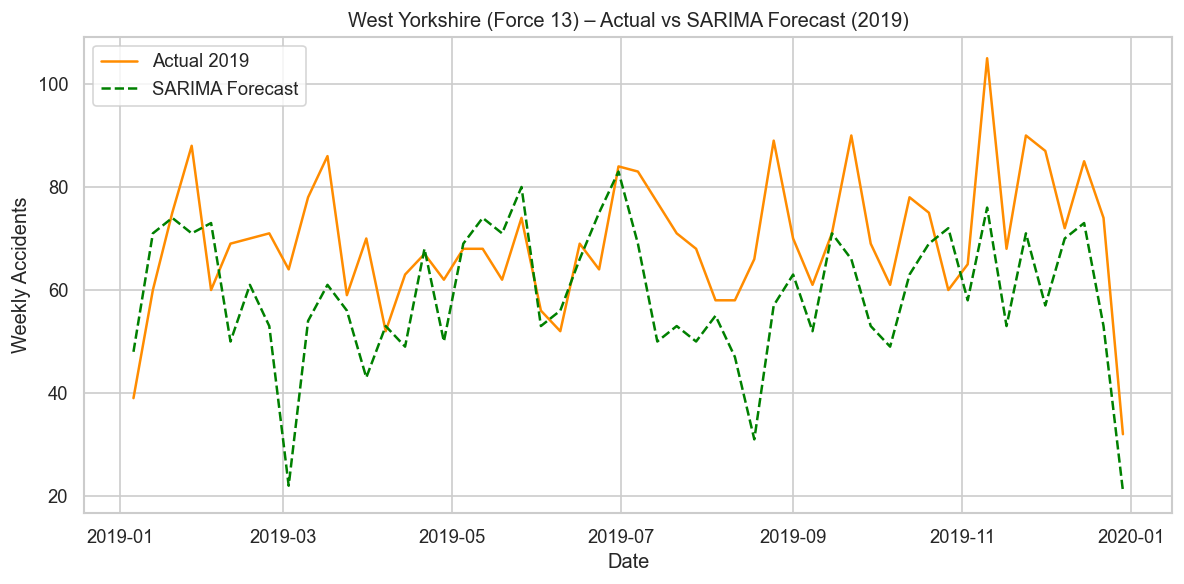

  RMSE=16.60  MAPE=18.97%

── Thames Valley (STATS20 Annex 6 code 43) ──
Thames Valley                   ADF= -5.257  p=0.0000  STATIONARY
  [Thames Valley] Best order: (0, 1, 0), AIC: 6.00


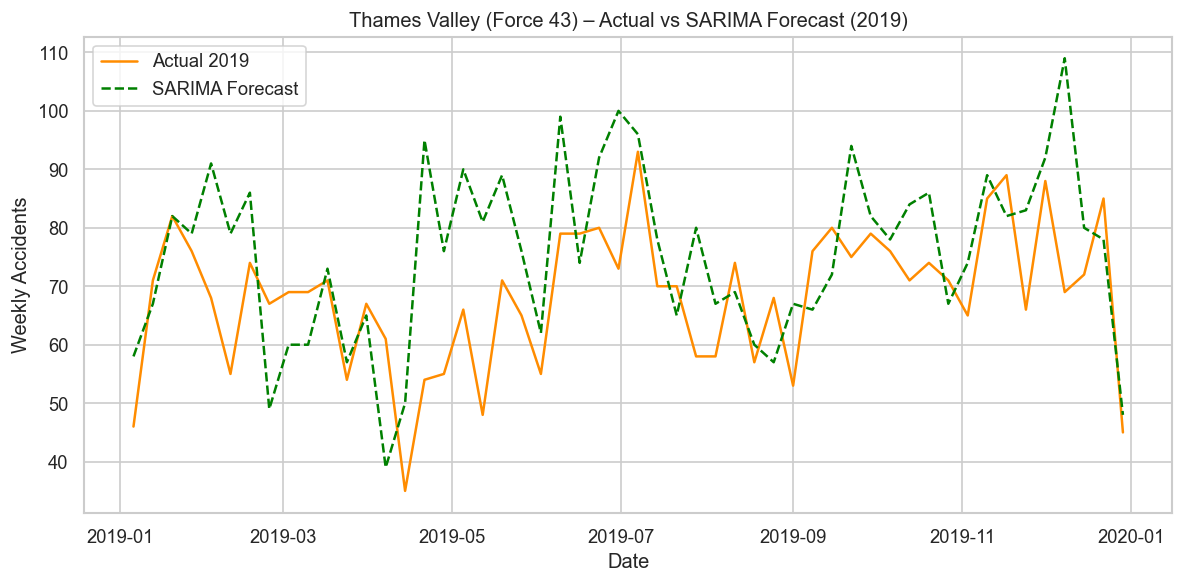

  RMSE=15.36  MAPE=19.16%


In [29]:
results_ts6 = {}

for code, name in POLICE_AREAS.items():

    print(f'\n── {name} (STATS20 Annex 6 code {code:02d}) ──')

    weekly = build_weekly_series(acc_multi, code)
    train  = weekly[weekly.index.year.isin([2017,2018])]
    test   = weekly[weekly.index.year == 2019]

    if train.empty or test.empty:
        print(f'  WARNING: missing data – skipping')
        continue

    adf_report(train, name)

    res = fit_sarima(train, test, name, seasonal_order=(1,1,1,52))
    results_ts6[name] = res

    # --- Individual plot per area ---
    plt.figure(figsize=(10,5))

    # Actual only
    plt.plot(test.index, test.values,
             label='Actual 2019', color='darkorange')

    # Forecast only
    plt.plot(res['forecast'].index, res['forecast'].values,
             label='SARIMA Forecast', color='green', linestyle='--')

    plt.title(f'{name} (Force {code:02d}) – Actual vs SARIMA Forecast (2019)')
    plt.xlabel('Date')
    plt.ylabel('Weekly Accidents')
    plt.legend()

    plt.tight_layout()
    plt.savefig(f'task6_sarima_{code}_{name}.png', bbox_inches='tight')
    plt.show()

    print(f'  RMSE={res["rmse"]:.2f}  MAPE={res["mape"]:.2f}%')

---
## Section 8 – Task 7: Top-30 LSOA Daily Forecast (West Yorkshire, 2018)

1. Filter West Yorkshire (police_force=**13**).
2. Aggregate **daily** counts for those 30 LSOAs over Jan-Jun 2018.
3. Fit SARIMA with **m=7** (weekly seasonality within daily data).
4. Forecast July 2018 and evaluate against actuals.

In [30]:
# Step 1 – Top 30 LSOAs by Q1 2018 accident count
wy_q1 = acc_2018[
    (acc_2018['police_force'] == WY_POLICE_CODE) &  # 13 = West Yorkshire
    (acc_2018['month'].isin([1,2,3]))
].copy()

lsoa_counts = (wy_q1.groupby('lsoa_of_accident_location')
               .size().sort_values(ascending=False))
top30_lsoas = lsoa_counts.head(30).index.tolist()

print(f'WY Q1 2018 accidents: {len(wy_q1):,}')
print(f'Unique LSOAs: {len(lsoa_counts)}')
print(f'Min count in top 30: {lsoa_counts.iloc[29]}')
print(lsoa_counts.head(30).to_string())

WY Q1 2018 accidents: 989
Unique LSOAs: 586
Min count in top 30: 4
lsoa_of_accident_location
E01011499    11
E01033693     8
E01011107     8
E01033010     8
E01010833     7
E01011236     7
E01011369     7
E01033005     6
E01011935     6
E01011569     6
E01011130     5
E01011363     5
E01011677     5
E01011428     5
E01033031     5
E01011468     5
E01011205     5
E01011523     5
E01010979     5
E01011297     5
E01010639     4
E01011671     4
E01010834     4
E01011907     4
E01011368     4
E01011626     4
E01011280     4
E01011923     4
E01011749     4
E01010994     4


Daily series: 181 days
count    181.000000
mean       1.480663
std        1.245397
min        0.000000
25%        1.000000
50%        1.000000
75%        2.000000
max        6.000000
Name: accident_count, dtype: float64


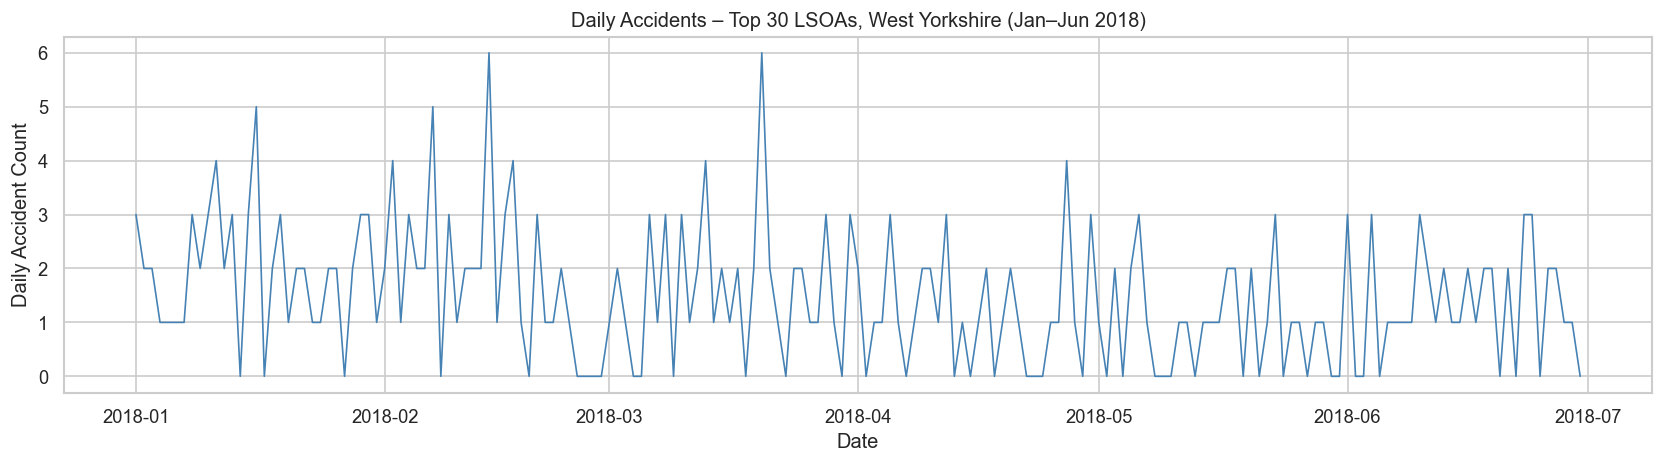

In [31]:
# Step 2 – Daily aggregation Jan–Jun 2018 for top-30 LSOAs
wy_h1 = acc_2018[
    (acc_2018['police_force'] == WY_POLICE_CODE) &
    (acc_2018['lsoa_of_accident_location'].isin(top30_lsoas)) &
    (acc_2018['month'].isin(range(1,7)))
].copy()

daily_ts = (wy_h1.set_index('date').resample('D')['accident_index'].count())
daily_ts.name = 'accident_count'
full_range = pd.date_range('2018-01-01','2018-06-30', freq='D')
daily_ts   = daily_ts.reindex(full_range, fill_value=0)

print(f'Daily series: {len(daily_ts)} days')
print(daily_ts.describe())

fig, ax = plt.subplots(figsize=(14,4))
ax.plot(daily_ts.index, daily_ts.values, color='steelblue', linewidth=1)
ax.set(title=(f'Daily Accidents – Top 30 LSOAs, '
              f'{POLICE_FORCE[WY_POLICE_CODE]} (Jan–Jun 2018)'),
       xlabel='Date', ylabel='Daily Accident Count')
plt.tight_layout()
plt.savefig('task7_h1_daily_series.png', bbox_inches='tight')
plt.show()

ADF test:
Top-30 LSOA daily               ADF= -2.991  p=0.0357  STATIONARY
After 1st-order differencing:
Top-30 LSOA diff(1)             ADF=-10.171  p=0.0000  STATIONARY


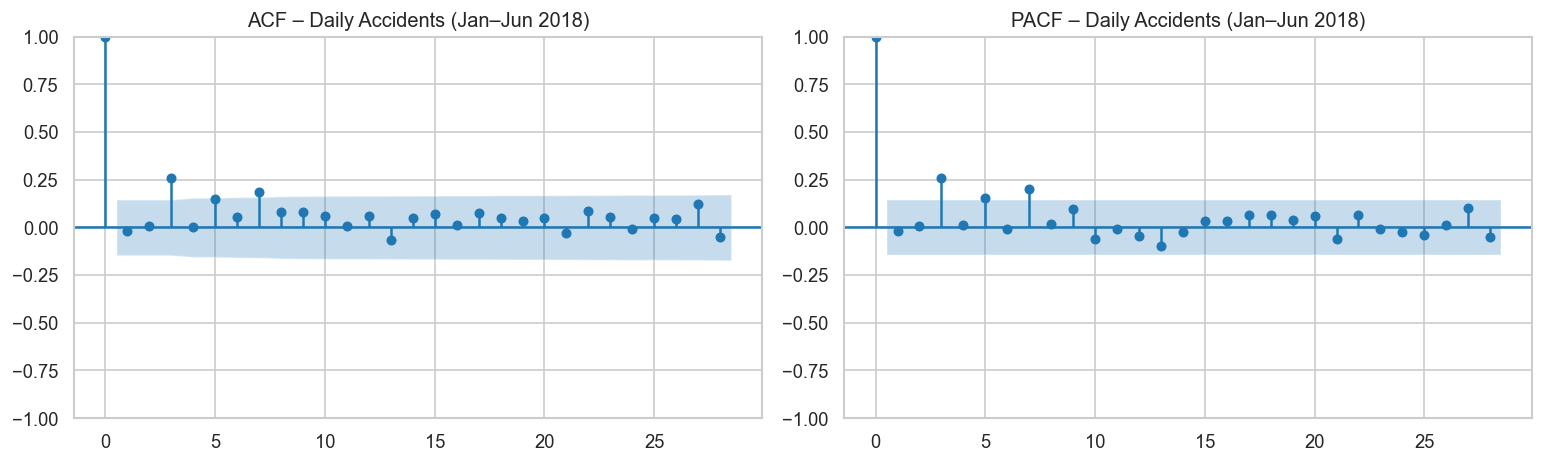

In [32]:
# Step 3 – Stationarity check + ACF/PACF
print('ADF test:')
adf_report(daily_ts, 'Top-30 LSOA daily')
diff1 = daily_ts.diff(1).dropna()
print('After 1st-order differencing:')
adf_report(diff1, 'Top-30 LSOA diff(1)')

fig, axes = plt.subplots(1, 2, figsize=(13,4))
plot_acf(daily_ts,  lags=28, ax=axes[0])
plot_pacf(daily_ts, lags=28, ax=axes[1])
axes[0].set_title('ACF – Daily Accidents (Jan–Jun 2018)')
axes[1].set_title('PACF – Daily Accidents (Jan–Jun 2018)')
plt.tight_layout()
plt.savefig('task7_acf_pacf.png', bbox_inches='tight')
plt.show()

In [33]:
# Step 4 – SARIMA grid search (m=7 weekly seasonality in daily data)
SEASONAL_M = 7
best_aic_t7, best_params_t7 = np.inf, None

for p, q, P, Q in itertools.product(range(3), range(3), range(2), range(2)):
    try:
        m = SARIMAX(daily_ts, order=(p,1,q),
                    seasonal_order=(P,1,Q,SEASONAL_M),
                    enforce_stationarity=False,
                    enforce_invertibility=False).fit(disp=False)
        if m.aic < best_aic_t7:
            best_aic_t7    = m.aic
            best_params_t7 = (p,1,q,P,1,Q)
    except Exception:
        continue

p,d,q,P,D,Q = best_params_t7
print(f'Best SARIMA({p},{d},{q})({P},{D},{Q},{SEASONAL_M}), AIC={best_aic_t7:.2f}')

Best SARIMA(2,1,2)(0,1,1,7), AIC=546.59


In [34]:
# Step 5 – Fit and forecast July 2018
sarima_t7 = SARIMAX(daily_ts, order=(p,d,q),
                    seasonal_order=(P,D,Q,SEASONAL_M),
                    enforce_stationarity=False,
                    enforce_invertibility=False).fit(disp=False)

FORECAST_DAYS  = 31
forecast_t7    = sarima_t7.forecast(steps=FORECAST_DAYS)
forecast_index = pd.date_range('2018-07-01', periods=FORECAST_DAYS, freq='D')
forecast_t7.index = forecast_index

# Actual July data for same 30 LSOAs
wy_jul = acc_2018[
    (acc_2018['police_force'] == WY_POLICE_CODE) &
    (acc_2018['lsoa_of_accident_location'].isin(top30_lsoas)) &
    (acc_2018['month'] == 7)
].copy()
actual_jul = (wy_jul.set_index('date').resample('D')['accident_index']
              .count().reindex(forecast_index, fill_value=0))

rmse_t7 = np.sqrt(mean_squared_error(actual_jul, forecast_t7))
mape_t7 = mean_absolute_percentage_error(actual_jul + 1e-6, forecast_t7) * 100
print(f'July 2018  RMSE={rmse_t7:.3f}  MAPE={mape_t7:.2f}%')

July 2018  RMSE=1.063  MAPE=49742224.61%



Task 7 Forecast Summary
Police Force: West Yorkshire (Code 13)
SARIMA(2,1,2)(0,1,1,7)
RMSE: 1.06 | MAPE: 49742224.6%


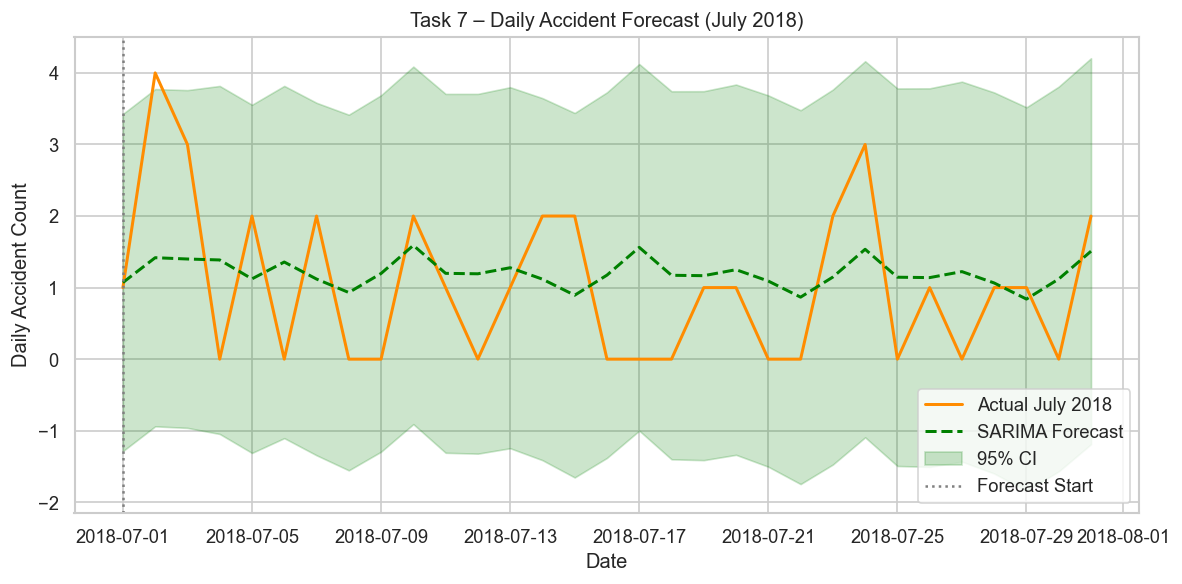

In [35]:
# Plot with 95% confidence interval
pred_ci = sarima_t7.get_forecast(steps=FORECAST_DAYS).conf_int()
pred_ci.index = forecast_index

# --- Print model details separately ---
print(f"\nTask 7 Forecast Summary")
print(f"Police Force: {POLICE_FORCE[WY_POLICE_CODE]} (Code {WY_POLICE_CODE:02d})")
print(f"SARIMA({p},{d},{q})({P},{D},{Q},{SEASONAL_M})")
print(f"RMSE: {rmse_t7:.2f} | MAPE: {mape_t7:.1f}%")

# --- Plot ---
fig, ax = plt.subplots(figsize=(10,5))

ax.plot(actual_jul.index, actual_jul.values,
        label='Actual July 2018', color='darkorange', linewidth=1.8)

ax.plot(forecast_t7.index, forecast_t7.values,
        label='SARIMA Forecast', color='green', linestyle='--', linewidth=1.8)

ax.fill_between(forecast_index,
                pred_ci.iloc[:,0], pred_ci.iloc[:,1],
                alpha=0.2, color='green', label='95% CI')

ax.axvline(pd.Timestamp('2018-07-01'), color='grey',
           linestyle=':', label='Forecast Start')

ax.set(
    title='Task 7 – Daily Accident Forecast (July 2018)',
    xlabel='Date',
    ylabel='Daily Accident Count'
)

ax.legend()
plt.tight_layout()
plt.savefig('task7_sarima_forecast_july.png', bbox_inches='tight')
plt.show()

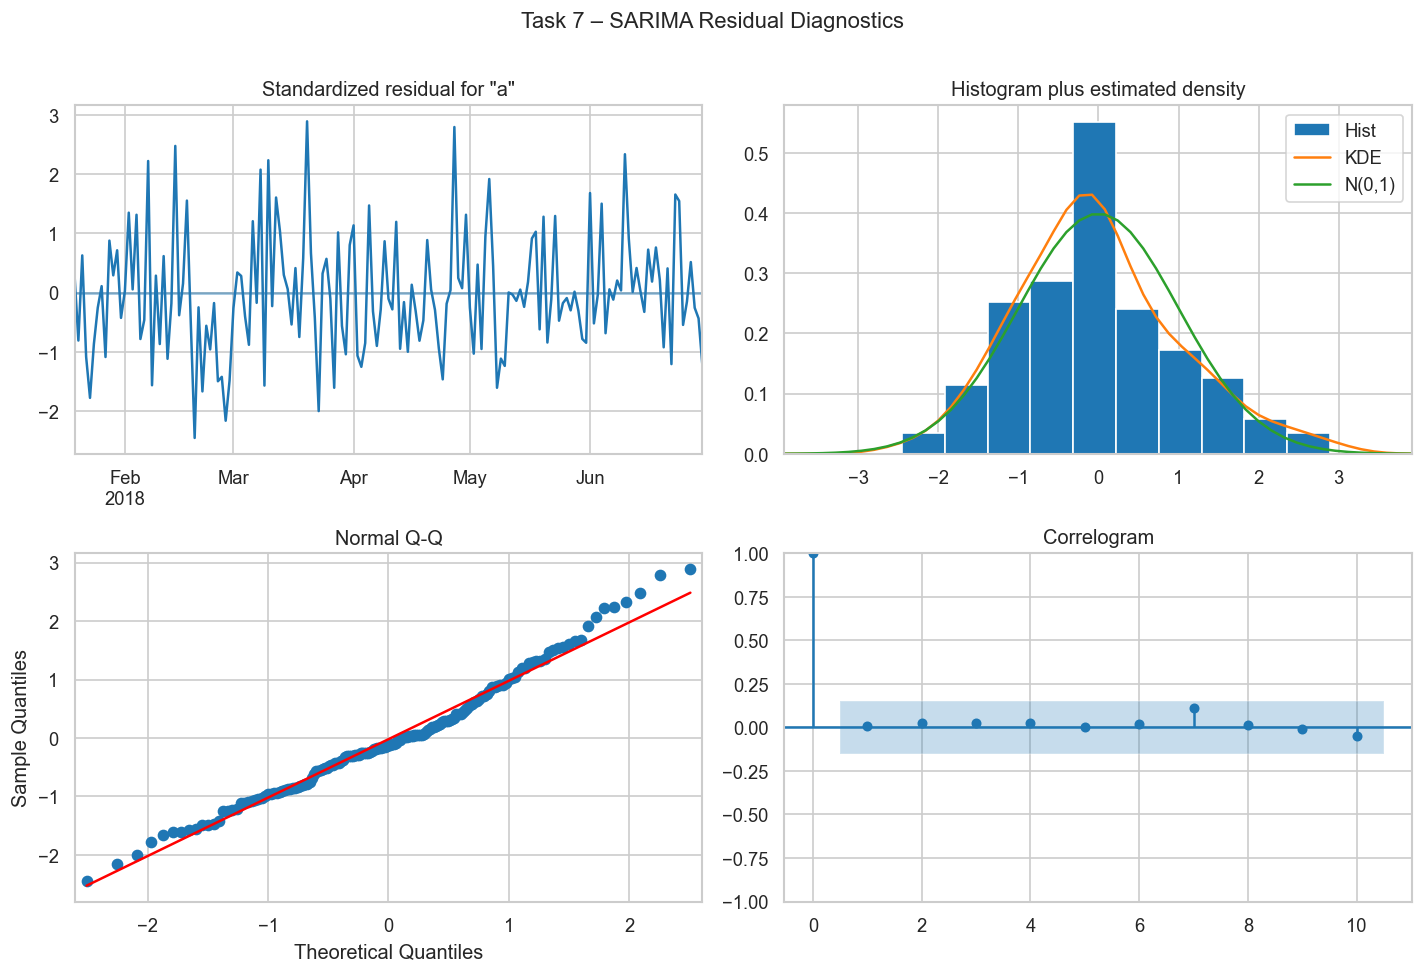

Ljung-Box test (Task 7):
     lb_stat  lb_pvalue
1   0.136391   0.711896
2   0.304705   0.858685
3   0.598368   0.896806
4   0.600636   0.962993
5   0.824921   0.975417
6   0.828996   0.991274
7   1.572511   0.979693
8   1.619020   0.990551
9   1.671588   0.995662
10  1.705403   0.998140

=== Notebook Complete ===


In [36]:
# Residual diagnostics
sarima_t7.plot_diagnostics(figsize=(12,8))
plt.suptitle('Task 7 – SARIMA Residual Diagnostics', y=1.01)
plt.tight_layout()
plt.savefig('task7_residuals.png', bbox_inches='tight')
plt.show()

lb_t7 = acorr_ljungbox(sarima_t7.resid, lags=10, return_df=True)
print('Ljung-Box test (Task 7):')
print(lb_t7.to_string())

print('\n=== Notebook Complete ===')